# **Hospital Operational Efficiency for elderly across U.S. regions**

****

**Team 10**


*   Ateh Nji-Tanji
*   Lujia Shao (Lydia)
*   Sophia Lee
*   Vicky Ye
*   Muntira Samalapa (View)



# **Problem Statement**
****

Operations efficiency is critical for healthcare systems because care delays can lead to worse outcomes, more complications, and overloaded hospitals. Currently, hospitals in the U.S. are facing rising occupancy rates and overcrowding problems. The Emergency Department is one of the departments that require action due to higher urgency. According to KFF Health News, within the Emergency Department, ER patients who are 65 years and older accounted for almost 20% of the total ER visits. This represents a huge demand for hospital services, and older adults are usually more vulnerable to the effects of hospital operational efficiency. Therefore, we want to investigate further on how operations efficiency differs within this target group across U.S. regions to understand each region and state differences in the efficiency.




**Data Sources**


* Timely and Effective Care by Hospital/States- NBER. (https://www.nber.org/research/data/centers-medicare-medicaid-services-cms-hospital-compare-data)
* Medicare Monthly Enrollment-Centers for Medicare & Medicaid Services Data
(https://data.cms.gov/summary-statistics-on-beneficiary-enrollment/medicare-and-medicaid-reports/medicare-monthly-enrollment/data)
* Rural-Urban Continuum Codes - USDA. (https://www.ers.usda.gov/data-products/rural-urban-continuum-codes)
* Population 65 Years and Over in the United States - United States Census Bureau. (https://www.census.gov/data/tables/time-series/demo/popest/2020s-state-detail.html)
* Provider of Services File - CMS. (https://data.cms.gov/provider-characteristics/hospitals-and-other-facilities/provider-of-services-file-quality-improvement-and-evaluation-system)
* Rural-Urban Commuting Area Codes by ZIP Code - USDA. (https://www.ers.usda.gov/data-products/rural-urban-commuting-area-codes)




# **Executive Summary**
****

**Objective**
<br>
Compare ED performance and hospital capacity across U.S. regions and rural–urban settings, considering population aging.

<br>**Findings**
* The Northeast had the longest median hospital ED visit-time
* Urban hospitals reported longer ED visits than rural hospitals
* The Northeast had the fewest hospitals per resident and the West had the fewest beds.
* Older population and Medicare enrollment increased, but older population share did not consistently correspond to longer ED visits.


<br>**Recommendations**
<br>
* Investigate other hospital size measures e.g. staffing, patient volume, and patient flow in Northeast hospitals.

* Examine staffed beds and occupancy, particulary in the west before recommending capacity expansion.

* Incorporate population aging into resource planning and considering age-specific ED data.


# **Methods**
****
We cleaned and standardized the following datasets: elderly population estimates, Medicare FFS enrollment, Timely and Effective Care by Hospital, the CMS Provider of Services facility file and 2020 RUCA ZIP code classifications. This was done by removing empty columns, standardizing text and date fields types, validating ZIP code formatting and separating valid missing values. For analysis, States were grouped into four U.S. regions, then, hospital, population and quality-of-care records were grouped by state and region. We investigated patterns using grouped statistics like totals, medians and per-capita rates. Finally we visualized them with line charts for trends over time, bar charts and histograms for distribution comparisons and a heatmap for regional performance across quality measures. Outliers in numeric care measures were identified using the IQR method.

# **Introduction**
****
**Motivation**
<br>Care delays and inconsistent hospital performance can affect healthcare quality and patient outcomes, especially amongst vulnerable population groups. We aim to identify disparities of hospital operational efficiency in treating elderly population between rural and urban regions.

# **Data Dictionary**
****

| Dataset Name | Column Name | Data Type | Description | Units |
|---|---|---|---|---|
| Population Estimates (cleaned: population) | `state` | String | Two-letter U.S. state abbreviation. | State code |
|  | `2020 elder – 2025 elder` | Integer | Estimated civilian population aged 65 and older for each year from 2020 through 2025. | Persons |
|  | `2020 total – 2025 total` | Integer | Estimated total civilian population for each year from 2020 through 2025. | Persons |
|  | `region` | String | U.S. Census-style region assigned from the state: Northeast, Midwest, South, or West. | Category |
| RUCA Codes (cleaned: clean_ruca) | `ZIPCode` | String | Original five-digit ZIP code, preserved as text to retain leading zeros. | ZIP code |
|  | `State` | String | Two-letter state abbreviation associated with the ZIP code. | State code |
|  | `ZIPCodeType` | String | Type of ZIP code geography. | Category |
|  | `POName` | String | Postal place name associated with the ZIP code. | N/A |
|  | `PrimaryRUCA` | String | Primary Rural-Urban Commuting Area classification code. | Code |
|  | `SecondaryRUCA` | Numeric | Secondary RUCA commuting-pattern classification code. | Code |
|  | `zip_code` | String | Cleaned ZIP code used for joining to hospital records. | ZIP code |
|  | `PrimaryRUCA_Label` | String | Human-readable label for the primary RUCA category. | Category |
|  | `commute_cat` | String | Grouped commuting classification: Metropolitan, Micropolitan, Small town, or Rural. | Category |
|  | `urban_rural` | String | Derived binary classification of ZIP codes as urban or rural. | Category |
| Timely and Effective Care by Hospital (cleaned: hospital_with_ruca) | `facility_id` | String / Identifier | CMS Certification Number used to identify the reporting hospital. | Identifier |
|  | `facility_name` | String | Name of reporting hospital. | N/A |
|  | `address` | String | Street address of the hospital. | N/A |
|  | `city` | String | City of the hospital. | N/A |
|  | `state` | String | Two-letter state abbreviation of the hospital. | State code |
|  | `zip_code` | String | Five-character postal code, padded with leading zeros for matching. | ZIP code |
|  | `county_name` | String | County of the hospital. | N/A |
|  | `phone_number` | String | Hospital telephone number. | Phone number |
|  | `condition` | String | Clinical measure category; the analysis focuses on Emergency Department. | Category |
|  | `measure_id` | String | CMS performance measure identifier (e.g., OP_18b, OP_22). | Measure code |
|  | `measure_name` | String | Description of the performance measure. | N/A |
|  | `score` | Numeric | Reported value of the performance measure; interpretation varies by measure. | Minutes or % |
|  | `sample` | Numeric | Number of observations in the reported measure sample. | Count |
|  | `footnote` | String / Numeric | CMS footnote code explaining data limitations or reporting details. | Code |
|  | `start_date` | Datetime | Beginning of the period covered by the reported measure. | Date |
|  | `end_date` | Datetime | End of the period covered by the reported measure. | Date |
|  | `urban_rural` | String | Rural/urban group linked from the RUCA ZIP code dataset. | Category |
|  | `analysis_year` | Integer | Calendar year extracted from the measure period end date. | Year |
| Medicare Monthly Enrollment (cleaned: year) | `year` | Integer | Calendar year of the state-level annual Medicare enrollment record. | Year |
|  | `state` | String | Two-letter state abbreviation. | State code |
|  | `disabled_total` | Numeric | Total Medicare beneficiaries enrolled on the basis of disability as represented by this source field. | Beneficiaries |
|  | `disabled_esrd_and_esrd_only` | Numeric | Disabled beneficiaries in the ESRD-related source category. | Beneficiaries |
|  | `disabled_without_esrd` | Numeric | Disabled beneficiaries without ESRD in the source category. | Beneficiaries |
|  | `enrollment_65_plus` | Numeric | Sum of Medicare beneficiaries in the source age groups 65–69 through older than 94. | Beneficiaries |
|  | `total_enrollment` | Numeric | Sum of Medicare beneficiaries across all reported age groups. | Beneficiaries |
| Timely and Effective Care by State + Enrollment (cleaned: state_22_18) | `state` | String | Two-letter state abbreviation used to merge sources. | State code |
|  | `enrollment_65_plus` | Numeric | Annual Medicare beneficiaries aged 65 and older in the state. | Beneficiaries |
|  | `total_enrollment` | Numeric | Annual Medicare beneficiaries of all ages in the state. | Beneficiaries |
|  | `ED_18` | Numeric | State-reported OP_18b: median emergency department visit duration for specified patients. | Minutes |
|  | `ED_22` | Numeric | State-reported OP_22: emergency department patients leaving before being seen. | % |
|  | `pct_65_plus` | Float | Population aged 65+ divided by state total population, multiplied by 100. | % |
|  | `medicare_pct_65_plus` | Float | Medicare enrollment aged 65+ divided by total Medicare enrollment, multiplied by 100. | % |
| CMS Provider of Services (cleaned: provider_active) | `CCN` | String | Six-character CMS Certification Number identifying the facility. | Identifier |
|  | `Facility_Name` | String | Registered name of the hospital/facility. | N/A |
|  | `State_Abbreviation` | String | Two-letter state abbreviation. | State code |
|  | `Address_ZIP_Code` | String | Facility ZIP code. | ZIP code |
|  | `Provider_Category_Subtype_Code` | String | CMS facility subtype identifier. | Code |
|  | `Bed_Count_Total` | Numeric | Reported total number of beds at the facility. | Beds |
|  | `Bed_Count_Certified` | Numeric | Reported number of certified beds. | Beds |
|  | `Ownership_Type_Code` | String | CMS code describing ownership category. | Code |
|  | `Services_Emergency_Department_Code` | String | CMS code indicating emergency department service status. | Code |
|  | `Ownership_Type` | String | Readable ownership type decoded from Ownership_Type_Code. | Category |
| Hospital + Provider Merge (cleaned: hospital_all) | `facility_id` | String | Hospital CMS Certification Numbers used to join care and facility data. | Identifier |
|  | `reh_hos` | String | Whether hospital was matched to rural emergency hospital reporting data. | Yes / No |
|  | `provider_match` | String | Result of the merge with the CMS Provider of Services file. | Merge status |
|  | `Bed_Count_Total` | Numeric | Facility bed counts added from the provider file. | Beds |
|  | `Bed_Count_Certified` | Numeric | Facility bed counts added from the provider file. | Beds |
|  | `Ownership_Type` | String | Facility ownership category added from the provider file. | Category |

#**Phase 1 Summary**

In the previous stage, we cleaned and standardized population, Medicare enrollment, hospital-provider, ED performance, and rural–urban classification datasets. We explored population and enrollment trends, facility bed counts, ED patient volumes, and regional hospital availability. Initial findings showed growth in the older population across all regions, greater hospital availability per resident in the Midwest and longer ED visits in the Northeast. We also identified missing scores and differing data periods as limitations.

# **Data Cleaning**
****

In [654]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import plotly.express as px

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [655]:
#Import all datasets here

#1 Population
population = pd.read_csv('/content/drive/MyDrive/Data_team10/2nd Phase /Data set/sc-est2025-agesex-civ.csv')

#2 Rural and Urban classification codes
ruca = pd.read_csv("/content/drive/MyDrive/Data_team10/2nd Phase /Data set/RUCA-codes-2020-zipcode.csv" ,dtype=str)

#3 Timely and Effective Care of Hospital
##2026 (mostly 2025 records)
hospital_data_nor26 = pd.read_csv('/content/drive/MyDrive/Data_team10/2nd Phase /Data set/2026timely_and_effective_care_hospital.csv')
hospital_data_reh26 = pd.read_csv('/content/drive/MyDrive/Data_team10/2nd Phase /Data set/reh2026_timely_and_effective_care_hospital.csv')
hospital_data_reh26['measure_id']=hospital_data_reh26['measure_id'].str.replace('REH_', '')
##2025
full_hospital_data25 = pd.read_csv('/content/drive/MyDrive/Data_team10/2nd Phase /Data set/2025timely_and_effective_care_hospital.csv')
##2024
full_hospital_data24 = pd.read_csv('/content/drive/MyDrive/Data_team10/2nd Phase /Data set/2024timely_and_effective_care_hospital.csv')
##2023
full_hospital_data23 = pd.read_csv('/content/drive/MyDrive/Data_team10/2nd Phase /Data set/2023timely_and_effective_care_hospital.csv')
##2022
full_hospital_data22 = pd.read_csv('/content/drive/MyDrive/Data_team10/2nd Phase /Data set/2022timely_and_effective_care_hospital.csv').rename(columns={'measureid': 'measure_id'})
##2021
full_hospital_data21 = pd.read_csv('/content/drive/MyDrive/Data_team10/2nd Phase /Data set/2021timely_and_effective_care_hospital.csv')
##2020
full_hospital_data20 = pd.read_csv('/content/drive/MyDrive/Data_team10/2nd Phase /Data set/2020timely_and_effective_care_hospital.csv')

#4 Timely and Effective Care by State
effective_care_2020 = pd.read_csv('/content/drive/MyDrive/Data_team10/2nd Phase /Data set/timely_and_effective_care_state-2020.csv')
effective_care_2021 = pd.read_csv('/content/drive/MyDrive/Data_team10/2nd Phase /Data set/Timely_and_Effective_Care-State_2021.csv')
effective_care_2022 = pd.read_csv('/content/drive/MyDrive/Data_team10/2nd Phase /Data set/timely_and_effective_care_state-2022.csv')
effective_care_2023 = pd.read_csv('/content/drive/MyDrive/Data_team10/2nd Phase /Data set/timely_and_effective_care_state_2023.csv')
effective_care_2024 = pd.read_csv('/content/drive/MyDrive/Data_team10/2nd Phase /Data set/timely_and_effective_care_state_2024.csv')
effective_care_2025 = pd.read_csv('/content/drive/MyDrive/Data_team10/2nd Phase /Data set/timely_and_effective_care_state_2025.csv')

#5 Medicare Monthly Enrollment
medicare = pd.read_csv('/content/drive/MyDrive/Data_team10/2nd Phase /Data set/Medicare_Monthly_Enrollment_Jun_2026.csv')

#Hospital information dataset
hospital_other = pd.read_csv("/content/drive/MyDrive/Data_team10/2nd Phase /Data set/Hospital_and_other_DATA_Q2_2026_RENAMED.csv", dtype=str)



/tmp/ipykernel_425/2427819935.py:11: DtypeWarning:

Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.

/tmp/ipykernel_425/2427819935.py:15: DtypeWarning:

Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.



**Define state and region**
<br>For consistency throughout the analysis and document

In [656]:
#States list
states = [
    "AL", "AK", "AZ", "AR", "CA", "CO", "CT", "DE",
    "FL", "GA", "HI", "ID", "IL", "IN", "IA", "KS",
    "KY", "LA", "ME", "MD", "MA", "MI", "MN", "MS",
    "MO", "MT", "NE", "NV", "NH", "NJ", "NM", "NY",
    "NC", "ND", "OH", "OK", "OR", "PA", "RI", "SC",
    "SD", "TN", "TX", "UT", "VT", "VA", "WA", "WV",
    "WI", "WY"]

#Define Regions
regions = {
    "Northeast": ["CT", "ME", "MA", "NH", "RI", "VT", "NJ", "NY", "PA"],
    "Midwest": ["IL", "IN", "MI", "OH", "WI","IA", "KS", "MN", "MO", "NE", "ND", "SD"],
    "South": ["DE", "FL", "GA", "MD", "NC", "SC", "VA", "WV","AL", "KY", "MS", "TN","AR", "LA", "OK", "TX"],
    "West": ["AZ", "CO", "ID", "MT", "NV", "NM", "UT", "WY","AK", "CA", "HI", "OR", "WA"]
}

#State Code
state_code = {
    "Alabama": "AL",
    "Alaska": "AK",
    "Arizona": "AZ",
    "Arkansas": "AR",
    "California": "CA",
    "Colorado": "CO",
    "Connecticut": "CT",
    "Delaware": "DE",
    "Florida": "FL",
    "Georgia": "GA",
    "Hawaii": "HI",
    "Idaho": "ID",
    "Illinois": "IL",
    "Indiana": "IN",
    "Iowa": "IA",
    "Kansas": "KS",
    "Kentucky": "KY",
    "Louisiana": "LA",
    "Maine": "ME",
    "Maryland": "MD",
    "Massachusetts": "MA",
    "Michigan": "MI",
    "Minnesota": "MN",
    "Mississippi": "MS",
    "Missouri": "MO",
    "Montana": "MT",
    "Nebraska": "NE",
    "Nevada": "NV",
    "New Hampshire": "NH",
    "New Jersey": "NJ",
    "New Mexico": "NM",
    "New York": "NY",
    "North Carolina": "NC",
    "North Dakota": "ND",
    "Ohio": "OH",
    "Oklahoma": "OK",
    "Oregon": "OR",
    "Pennsylvania": "PA",
    "Rhode Island": "RI",
    "South Carolina": "SC",
    "South Dakota": "SD",
    "Tennessee": "TN",
    "Texas": "TX",
    "Utah": "UT",
    "Vermont": "VT",
    "Virginia": "VA",
    "Washington": "WA",
    "West Virginia": "WV",
    "Wisconsin": "WI",
    "Wyoming": "WY"
}

**Dataset #1: Population**


In [657]:
population.head()

,SUMLEV,REGION,DIVISION,STATE,NAME,SEX,AGE,ESTBASE2020_CIV,POPEST2020_CIV,POPEST2021_CIV,POPEST2022_CIV,POPEST2023_CIV,POPEST2024_CIV,POPEST2025_CIV
0,10,0,0,0,United States,0,0,3719470,3691723,3572165,3680529,3653453,3617221,3618898
1,10,0,0,0,United States,0,1,3764281,3750601,3697247,3602579,3719819,3700305,3642657
2,10,0,0,0,United States,0,2,3841150,3826776,3756935,3727216,3642279,3766783,3725891
3,10,0,0,0,United States,0,3,3916585,3888055,3832978,3786311,3766965,3689270,3791993
4,10,0,0,0,United States,0,4,3984785,3976772,3894042,3861295,3824021,3811156,3712428


In [658]:
#cleaning
population = population.drop(columns=['REGION', 'DIVISION','SUMLEV','ESTBASE2020_CIV'])

population.rename(columns={'POPEST2020_CIV': '2020',
                           'POPEST2021_CIV': '2021',
                           'POPEST2022_CIV': '2022',
                           'POPEST2023_CIV': '2023',
                           'POPEST2024_CIV': '2024',
                           'POPEST2025_CIV': '2025',
                           }, inplace=True)

In [659]:

#only keep sex == 0, which means total population for both. male and female. And keep state that's not = 0, drop the national counts.
population = population[
    (population['SEX'] == 0)
    & (population['STATE'] != 0)]

#select age 999, which means the total population for that state.
total_population = population[population['AGE'] == 999].copy()
total_population = total_population.drop(columns=['SEX', 'AGE', 'STATE'])
total_population = total_population.rename(
    columns={'NAME': 'state',
             '2020':'2020 total',
             '2021':'2021 total',
             '2022':'2022 total',
             '2023':'2023 total',
             '2024':'2024 total',
             '2025':'2025 total'})



In [660]:
#delete the row that age = 999, only keep the population for every age, ensure not double population when we do the sum.
population = population[(population['AGE'] != 999)]

#drop the sex column, cause is been filtered, no need anymore
population = population.drop(columns=['SEX'])

year = ['2020', '2021', '2022', '2023', '2024', '2025']

elder_population = population[population["AGE"] >= 65]
elder_population = elder_population.groupby(['STATE','NAME'])[year].sum().reset_index()
elder_population.drop(columns=['STATE'], inplace=True)
elder_population = elder_population.rename(columns={
    'NAME':'state',
    '2020':'2020 elder',
    '2021':'2021 elder',
    '2022':'2022 elder',
    '2023':'2023 elder',
    '2024':'2024 elder',
    '2025':'2025 elder',
    })


In [661]:
population = pd.merge(total_population, elder_population, on='state')
population = population[[
    'state',
    '2020 elder',
    '2020 total',
    '2021 elder',
    '2021 total',
    '2022 elder',
    '2022 total',
    '2023 elder',
    '2023 total',
    '2024 elder',
    '2024 total',
    '2025 elder',
    '2025 total',
]]

population["state"] = population["state"].replace(state_code)

population = population[population["state"].isin(state_code.values())]
population.reset_index(drop=True, inplace=True)

population.head()

,state,2020 elder,2020 total,2021 elder,2021 total,2022 elder,2022 total,2023 elder,2023 total,2024 elder,2024 total,2025 elder,2025 total
0,AL,888925,5020504,904683,5037300,928635,5065770,956453,5106466,983383,5151592,1009814,5181269
1,AK,96062,711560,100633,712293,104525,711502,108656,712906,112414,714938,116192,715760
2,AZ,1344960,7166260,1389794,7254264,1432117,7351886,1478895,7434897,1526297,7539516,1571773,7607079
3,AR,530697,3010462,538902,3023310,551102,3043670,565030,3066097,578601,3092342,591966,3111133
4,CA,6023283,39382105,6161395,39006366,6325202,38982560,6511290,39044130,6710362,39229482,6901168,39222235



* Year columns were renamed for consistency
* Unwanted columns were dropped
* Filtered population data by age (>65)
* Replaced state names with state codes



**Dataset #2: Rural and Urban region classification**

In [662]:
ruca.isna().sum()

count = 0
for i in ruca["ZIPCode"]:
    if len(i) < 5:
        count +=1

print(f'Number of invalid zipcode is : {count}')

def Check_whitespace(column):
    count = 0
    for i in column:
        if ' ' in i:
            count += 1
    if count > 0:
        print(f"{column.name} contains {count} with whitespace")
    else:
        print(f"{column.name} contains 0 whitespace")

Check_whitespace(ruca['State'])
Check_whitespace(ruca['ZIPCodeType'])
Check_whitespace(ruca["POName"])
Check_whitespace(ruca['PrimaryRUCA'])
Check_whitespace(ruca["SecondaryRUCA"])


clean_ruca = ruca.copy()
clean_ruca['zip_code'] = clean_ruca['ZIPCode'].str.strip()
clean_ruca = clean_ruca.drop(columns = ['ZIPCode'])

for i in clean_ruca.columns:
    clean_ruca[i] = clean_ruca[i].str.strip()


count = 0
for i in clean_ruca["zip_code"]:
    if len(i) < 5:
        count +=1

print(f'Number of invalid zipcode is : {count}')

primary = {
    '1': 'Metropolitan core',
    '2': 'Metropolitan high commuting',
    '3': 'Metropolitan low commuting',
    '4': 'Micropolitan core',
    '5': 'Micropolitan high commuting',
    '6': 'Micropolitan low commuting',
    '7': 'Small town core',
    '8': 'Small town high commuting',
    '9': 'Small town low commuting',
    '10': 'Rural area',
    '99': 'Not coded (water only)',
}
clean_ruca['PrimaryRUCA_Label'] = clean_ruca['PrimaryRUCA'].map(primary)

Number of invalid zipcode is : 0
State contains 0 whitespace
ZIPCodeType contains 41146 with whitespace
POName contains 10127 with whitespace
PrimaryRUCA contains 0 whitespace
SecondaryRUCA contains 0 whitespace
Number of invalid zipcode is : 0


In [663]:
clean_ruca['SecondaryRUCA'] = pd.to_numeric(clean_ruca['SecondaryRUCA'], errors='coerce')
commuting_groups = {
    'Metropolitan': [1.0, 1.1, 2.0, 2.1, 4.1, 5.1, 7.1, 8.1, 10.1],
    'Micropolitan': [4.0, 5.0, 7.2, 8.2, 10.2],
    'Small town': [7.0, 8.0, 10.3],
    'Rural': [3.0, 6.0, 9.0, 10.0]}

clean_ruca['commute_cat'] = pd.NA
for category, codes in commuting_groups.items():
    clean_ruca.loc[clean_ruca['SecondaryRUCA'].isin(codes), 'commute_cat'] = category

In [664]:
urban_labels = [
    "Metropolitan core",
    "Metropolitan high commuting",
    "Metropolitan low commuting",
]

rural_labels = [
    "Micropolitan core",
    "Micropolitan high commuting",
    "Micropolitan low commuting",
    "Small town core",
    "Small town high commuting",
    "Small town low commuting",
    "Rural area",
]

clean_ruca['urban_rural'] = pd.NA
clean_ruca.loc[clean_ruca['PrimaryRUCA_Label'].isin(urban_labels),'urban_rural']='urban'
clean_ruca.loc[clean_ruca['PrimaryRUCA_Label'].isin(rural_labels),'urban_rural']='rural'

* Removed whitespace
* Checked for consitency amongst zip codes
* Mapped community codes to value
* Converted primary and secondary codes to commuter info

In [665]:
clean_ruca.pivot_table( values="zip_code", index="commute_cat", columns="urban_rural", aggfunc="count", fill_value=0)

urban_rural,rural,urban
commute_cat,,
Metropolitan,454,22200
Micropolitan,4501,0
Rural,10958,1181
Small town,1852,0


**Dataset #3: Timely and Effecitve Care by Hospital**


In [666]:
#pre-merge the 2026 timely and effective care by hospital
match_keys = ['address', 'zip_code', 'state', 'measure_id']

reh_cols = match_keys + ['facility_id', 'score', 'sample', 'footnote']
reh_data = hospital_data_reh26[reh_cols].copy()
reh_data['reh_hos'] = 'yes'

full_hospital_data26 = hospital_data_nor26.merge(reh_data, on=match_keys, how='left', suffixes=('', '_reh'),validate='many_to_one')

#Fill in missing scores, sample counts, and active facility_id from REH data
# AI Assistance (Sophia): clarified regulatory cause of identical facilities having different facility IDs, row-level coalescing of missing values using .combine_first()
full_hospital_data26['score'] = full_hospital_data26['score_reh'].combine_first(full_hospital_data26['score'])
full_hospital_data26['sample'] = full_hospital_data26['sample_reh'].combine_first(full_hospital_data26['sample'])
full_hospital_data26['facility_id'] = full_hospital_data26['facility_id_reh'].combine_first(full_hospital_data26['facility_id'])

full_hospital_data26['reh_hos'] = full_hospital_data26['reh_hos'].fillna('no')
full_hospital_data26.loc[full_hospital_data26['reh_hos'] == 'yes', 'footnote'] = full_hospital_data26.loc[full_hospital_data26['reh_hos'] == 'yes', 'footnote_reh']
full_hospital_data26 = full_hospital_data26.drop(columns=['score_reh', 'sample_reh', 'facility_id_reh','footnote_reh'])

In the CMS public release architecture prior to 2026, all facility-level records were housed in a single general hospital file. So no merged needed.

In [667]:
territories=['PR', 'VI', 'GU', 'AS', 'MP']
#2026 full dataset cleaning
#focus on ED condition
full_ed_hospital_data26 =full_hospital_data26[full_hospital_data26['condition']=='Emergency Department']
#remove the US territories
full_ed_hospital_data26 = full_ed_hospital_data26[~full_ed_hospital_data26['state'].isin(territories)]

#Exclude EDV category rows directly, EDV is the measurement for categorical (e.g., low, medium, high, very high)
full_ed_hospital_data26 = full_ed_hospital_data26[full_ed_hospital_data26['measure_id'] != 'EDV']
# Explicit footnote handling rules (footnote explain why there's missing value in score for the row):
# Footnotes 1, 5, 7, 12, 19: Excluded via .notna(): no score available
# Footnote 2: Excluded: sample too small, statistically unreliable
# Footnote 3: Retained (valid score present, shorter collection window)
# Footnote 4: Excluded: data suppressed by CMS / data not available for this period
# Footnote 28/ 29: Excluded: data is suppressed due to an extraordinary circumstances exception (e.g., natural disaster, system failure, public health emergency).
# Unannotated / NaN: Retained (standard valid scores)
drop_footnotes = [1.0, 2.0, 4.0, 5.0, 7.0, 12.0, 19.0, 28.0, 29.0]
full_ed_hospital_data26 = full_ed_hospital_data26[~full_ed_hospital_data26['footnote'].isin(drop_footnotes)].reset_index(drop=True)
#Drop the unannotated null scores (the 662 rows, results & reasons below)
full_ed_hospital_data26 = full_ed_hospital_data26.dropna(subset=['score']).reset_index(drop=True)

#2025
#focus on ED condition
full_ed_hospital_data25 =full_hospital_data25[full_hospital_data25['condition']=='Emergency Department']
#remove the US territories
full_ed_hospital_data25 = full_ed_hospital_data25[~full_ed_hospital_data25['state'].isin(territories)]
#Exclude EDV category rows directly, EDV is the measurement for categorical (e.g., low, medium, high, very high)
full_ed_hospital_data25 = full_ed_hospital_data25[full_ed_hospital_data25['measure_id'] != 'EDV']
full_ed_hospital_data25 = full_ed_hospital_data25[~full_ed_hospital_data25['footnote'].isin(drop_footnotes)].reset_index(drop=True)
#Drop the unannotated null scores
full_ed_hospital_data25 = full_ed_hospital_data25.dropna(subset=['score']).reset_index(drop=True)

#2024
#focus on ED condition
full_ed_hospital_data24 =full_hospital_data24[full_hospital_data24['condition']=='Emergency Department']
#remove the US territories
full_ed_hospital_data24 = full_ed_hospital_data24[~full_ed_hospital_data24['state'].isin(territories)]
#Exclude EDV category rows directly, EDV is the measurement for categorical (e.g., low, medium, high, very high)
full_ed_hospital_data24 = full_ed_hospital_data24[full_ed_hospital_data24['measure_id'] != 'EDV']
full_ed_hospital_data24 = full_ed_hospital_data24[~full_ed_hospital_data24['footnote'].isin(drop_footnotes)].reset_index(drop=True)
#Drop the unannotated null scores
full_ed_hospital_data24 = full_ed_hospital_data24.dropna(subset=['score']).reset_index(drop=True)

#2023
#focus on ED condition
full_ed_hospital_data23 =full_hospital_data23[full_hospital_data23['condition']=='Emergency Department']
#remove the US territories
full_ed_hospital_data23 = full_ed_hospital_data23[~full_ed_hospital_data23['state'].isin(territories)]
#Exclude EDV category rows directly, EDV is the measurement for categorical (e.g., low, medium, high, very high)
full_ed_hospital_data23 = full_ed_hospital_data23[full_ed_hospital_data23['measure_id'] != 'EDV']
full_ed_hospital_data23 = full_ed_hospital_data23[~full_ed_hospital_data23['footnote'].isin(drop_footnotes)].reset_index(drop=True)
#Drop the unannotated null scores
full_ed_hospital_data23 = full_ed_hospital_data23.dropna(subset=['score']).reset_index(drop=True)

#2022
#focus on ED condition
full_ed_hospital_data22 =full_hospital_data22[full_hospital_data22['condition']=='Emergency Department']
#remove the US territories
full_ed_hospital_data22 = full_ed_hospital_data22[~full_ed_hospital_data22['state'].isin(territories)]
#Exclude EDV category rows directly, EDV is the measurement for categorical (e.g., low, medium, high, very high)
full_ed_hospital_data22 = full_ed_hospital_data22[full_ed_hospital_data22['measure_id'] != 'EDV']
full_ed_hospital_data22 = full_ed_hospital_data22[~full_ed_hospital_data22['footnote'].isin(drop_footnotes)].reset_index(drop=True)
#Drop the unannotated null scores
full_ed_hospital_data22 = full_ed_hospital_data22.dropna(subset=['score']).reset_index(drop=True)

#2021
#focus on ED condition
full_ed_hospital_data21 =full_hospital_data21[full_hospital_data21['condition']=='Emergency Department']
#remove the US territories
full_ed_hospital_data21 = full_ed_hospital_data21[~full_ed_hospital_data21['state'].isin(territories)]
#Exclude EDV category rows directly, EDV is the measurement for categorical (e.g., low, medium, high, very high)
full_ed_hospital_data21 = full_ed_hospital_data21[full_ed_hospital_data21['measure_id'] != 'EDV']
full_ed_hospital_data21 = full_ed_hospital_data21[~full_ed_hospital_data21['footnote'].isin(drop_footnotes)].reset_index(drop=True)
#Drop the unannotated null scores
full_ed_hospital_data21 = full_ed_hospital_data21.dropna(subset=['score']).reset_index(drop=True)

#2020
#focus on ED condition
full_ed_hospital_data20 =full_hospital_data20[full_hospital_data20['condition']=='Emergency Department']
#remove the US territories
full_ed_hospital_data20 = full_ed_hospital_data20[~full_ed_hospital_data20['state'].isin(territories)]
#Exclude EDV category rows directly, EDV is the measurement for categorical (e.g., low, medium, high, very high)
full_ed_hospital_data20 = full_ed_hospital_data20[full_ed_hospital_data20['measure_id'] != 'EDV']
full_ed_hospital_data20 = full_ed_hospital_data20[~full_ed_hospital_data20['footnote'].isin(drop_footnotes)].reset_index(drop=True)
#Drop the unannotated null scores
full_ed_hospital_data20 = full_ed_hospital_data20.dropna(subset=['score']).reset_index(drop=True)


This section cleans the 'Timely and Effective Care by Hospital" data from 2020 to 2026. Before cleaning, we merged the 2026 general hospital data with the 2026 REH data. 2026 is the only year in which Rural Emergency Hospitals (REHs) are reported separately from general hospitals, because REHs operate differently from full-service hospitals, they needed to be handled with care. Some `Score` values that are missing in the general hospital data are available in the REH data, so the merge also fills those gaps to make the scores as complete as possible. The result is stored as `full_hospital_data26`.

Next, for all the years datasets, we removed U.S. territories and dropped all rows in the EDV category. EDV is a categorical measure (e.g., low, medium, high, very high), so it cannot be used in our quantitative analysis of emergency department (ED) measures.

We then handled the remaining missing `Score` values. Each missing score comes with a footnote explaining why it is missing, so we reviewed these footnote descriptions and dropped the rows whose reasons made them unusable for our analysis. We also dropped rows with null scores that had no footnote. Since our later analysis relies on the `Score` column to measure efficiency, we needed every remaining row to have a valid score. After these steps, no missing values remain in `Score`.

**Dataset #4: Timely and Effective Care by State**


In [668]:
#convert each reporting-period end date to datetime, then derive its calendar year (add by Sophia)
effective_care_2020['end_date'] = pd.to_datetime(effective_care_2020['end_date'], errors='coerce')
effective_care_2020['year'] = effective_care_2020['end_date'].dt.year

effective_care_2021['End Date'] = pd.to_datetime(effective_care_2021['End Date'], errors='coerce')
effective_care_2021['year'] = effective_care_2021['End Date'].dt.year

effective_care_2022['end_date'] = pd.to_datetime(effective_care_2022['end_date'], errors='coerce')
effective_care_2022['year'] = effective_care_2022['end_date'].dt.year

effective_care_2023['end_date'] = pd.to_datetime(effective_care_2023['end_date'], errors='coerce')
effective_care_2023['year'] = effective_care_2023['end_date'].dt.year

effective_care_2024['end_date'] = pd.to_datetime(effective_care_2024['end_date'], errors='coerce')
effective_care_2024['year'] = effective_care_2024['end_date'].dt.year

effective_care_2025['end_date'] = pd.to_datetime(effective_care_2025['end_date'], errors='coerce')
effective_care_2025['year'] = effective_care_2025['end_date'].dt.year

In [669]:
#rename effective_care_2021 col names
effective_care_2021.rename(columns={'State':'state', 'Condition':'condition','Measure ID':'measure_id','Measure Name':'measure_name','Score':'score','Footnote':'footnote','Start Date':'start_date','End Date':'end_date'}, inplace=True)
effective_care_2021.columns

Index(['state', 'condition', 'measure_id', 'measure_name', 'score', 'footnote',
       'start_date', 'end_date', 'year'],
      dtype='object')

In [670]:
#drop the unused column that is not related to our later analysis
effective_care_2020 = effective_care_2020.drop(columns=['start_date','end_date'])
effective_care_2021 = effective_care_2021.drop(columns=['start_date','end_date'])
effective_care_2022 = effective_care_2022.drop(columns=['start_date','end_date'])
effective_care_2023 = effective_care_2023.drop(columns=['start_date','end_date'])
effective_care_2024 = effective_care_2024.drop(columns=['start_date','end_date'])
effective_care_2025 = effective_care_2025.drop(columns=['start_date','end_date'])
#focus on ED
effective_care_2020 = effective_care_2020[effective_care_2020['condition'] == 'Emergency Department']
effective_care_2021 = effective_care_2021[effective_care_2021['condition'] == 'Emergency Department']
effective_care_2022 = effective_care_2022[effective_care_2022['condition'] == 'Emergency Department']
effective_care_2023 = effective_care_2023[effective_care_2023['condition'] == 'Emergency Department']
effective_care_2024 = effective_care_2024[effective_care_2024['condition'] == 'Emergency Department']
effective_care_2025 = effective_care_2025[effective_care_2025['condition'] == 'Emergency Department']
#select our target measuremets of ED
effective_care_2020 = effective_care_2020[
    effective_care_2020['measure_id'].isin (['OP_18b', 'OP_22'])].reset_index(drop=True)
effective_care_2021 = effective_care_2021[
    effective_care_2021['measure_id'].isin (['OP_18b', 'OP_22'])].reset_index(drop=True)
effective_care_2022 = effective_care_2022[
    effective_care_2022['measure_id'].isin (['OP_18b', 'OP_22'])].reset_index(drop=True)
effective_care_2023 = effective_care_2023[
    effective_care_2023['measure_id'].isin (['OP_18b', 'OP_22'])].reset_index(drop=True)
effective_care_2024 = effective_care_2024[
    effective_care_2024['measure_id'].isin (['OP_18b', 'OP_22'])].reset_index(drop=True)
effective_care_2025 = effective_care_2025[
    effective_care_2025['measure_id'].isin (['OP_18b', 'OP_22'])].reset_index(drop=True)
effective_care_2025.head(2)

,state,condition,measure_id,measure_name,score,footnote,year
0,AK,Emergency Department,OP_18b,Average (median) time patients spent in the em...,136.0,NaN,2025
1,AK,Emergency Department,OP_22,Percentage of patients who left the emergency ...,1.0,NaN,2024


In [671]:
#seperate the 2 measurements into 2 dataframes
op18_2020 = effective_care_2020[effective_care_2020['measure_id'] == 'OP_18b'].reset_index(drop=True)
op22_2020 = effective_care_2020[effective_care_2020['measure_id'] == 'OP_22'].reset_index(drop=True)

op18_2021 =effective_care_2021[effective_care_2021['measure_id'] == 'OP_18b'].reset_index(drop=True)
op22_2021 =effective_care_2021[effective_care_2021['measure_id'] == 'OP_22'].reset_index(drop=True)

op18_2022 = effective_care_2022[effective_care_2022['measure_id'] == 'OP_18b'].reset_index(drop=True)
op22_2022 = effective_care_2022[effective_care_2022['measure_id'] == 'OP_22'].reset_index(drop=True)

op18_2023 = effective_care_2023[effective_care_2023['measure_id'] == 'OP_18b'].reset_index(drop=True)
op22_2023 = effective_care_2023[effective_care_2023['measure_id'] == 'OP_22'].reset_index(drop=True)

op18_2024 = effective_care_2024[effective_care_2024['measure_id'] == 'OP_18b'].reset_index(drop=True)
op22_2024 = effective_care_2024[effective_care_2024['measure_id'] == 'OP_22'].reset_index(drop=True)

op18_2025 = effective_care_2025[effective_care_2025['measure_id'] == 'OP_18b'].reset_index(drop=True)
op22_2025 = effective_care_2025[effective_care_2025['measure_id'] == 'OP_22'].reset_index(drop=True)

In [672]:
#combine all the op18 to one file and op22 to another file
op18_df = {
    2020: op18_2020,
    2021: op18_2021,
    2022: op18_2022,
    2023: op18_2023,
    2024: op18_2024,
    2025: op18_2025
}

op18_yearly_data = []

for year, df in op18_df.items():
    df_copy = df.copy()
    op18_yearly_data.append(df_copy)

op18_state_data_years = pd.concat(op18_yearly_data, ignore_index=True)


op22_df = {
    2020: op22_2020,
    2021: op22_2021,
    2022: op22_2022,
    2023: op22_2023,
    2024: op22_2024,
    2025: op22_2025
}

op22_yearly_data = []

for year1, df1 in op22_df.items():
    df_copy1 = df1.copy()
    op22_yearly_data.append(df_copy1)

op22_state_data_years = pd.concat(op22_yearly_data, ignore_index=True)

In [673]:
#check if footnote 5 corresponds exactly to a missing or “Not Available” score (y)
df = op18_state_data_years

score_text = df['score'].astype('string').str.strip()

# Missing = real blank OR the text 'Not Available'. Assisted by ai to use .eq() (Sophia)
missing_score = df['score'].isna() | score_text.eq('Not Available')
print('Missing or Not Available scores:', missing_score.sum())

# Footnote as a number (blank or combined values like "5, 25" become NaN)
footnote_num = pd.to_numeric(df['footnote'], errors='coerce')

print('\nFootnotes on rows with missing score:')
print(footnote_num[missing_score].value_counts(dropna=False))

print('\nMissing-score rows without footnote 5:', (missing_score & footnote_num.ne(5)).sum()) #assisted by ai of footnote_num.ne(5): not equal 5 (Sophia)
print('Footnote 5 rows that still have a score:', ((footnote_num == 5) & ~missing_score).sum())

Missing or Not Available scores: 24

Footnotes on rows with missing score:
footnote
5.0    24
Name: count, dtype: int64

Missing-score rows without footnote 5: 0
Footnote 5 rows that still have a score: 0


In [674]:
#redo the same thing with op22_state_data_years (y)
df2 = op22_state_data_years

score_text2 = df2['score'].astype('string').str.strip()

# Missing = real blank OR the text 'Not Available'
missing_score2 = df2['score'].isna() | score_text2.eq('Not Available')
print('Missing or Not Available scores:', missing_score2.sum())

# Footnote as a number (blank or combined values like "5, 25" become NaN)
footnote_num2 = pd.to_numeric(df2['footnote'], errors='coerce')

print('\nFootnotes on rows with missing score:')
print(footnote_num2[missing_score2].value_counts(dropna=False))

print('\nMissing-score rows without footnote 5:', (missing_score2 & footnote_num2.ne(5)).sum())
print('Footnote 5 rows that still have a score:', ((footnote_num2 == 5) & ~missing_score2).sum())

Missing or Not Available scores: 24

Footnotes on rows with missing score:
footnote
5.0    24
Name: count, dtype: int64

Missing-score rows without footnote 5: 0
Footnote 5 rows that still have a score: 0


In [675]:
#remove US territories
op18_state_data_years=op18_state_data_years.dropna(subset=['score'])
op18_state_data_years = op18_state_data_years[~op18_state_data_years['state'].isin(territories)]
op22_state_data_years=op22_state_data_years.dropna(subset=['score'])
op22_state_data_years = op22_state_data_years[~op22_state_data_years['state'].isin(territories)]

For this section, we first cleaned the date fields in the "Timely and Effective Care by State" data. Since we only need the year, we used `end_date` as the year in which care was completed and recorded.

Next, we dropped the columns we did not need for our later analysis. We then narrowed our focus to emergency department (ED) conditions and two measures, OP_18b and OP_22, because they are the only ones recorded in every year we analyze.

Finally, we split the data by measure and combined each measure's records across years into a single file. We also removed U.S. territories so that all regions in our analysis are at the same level.

**Dataset #5: Medicare Monthly Enrollment**



In [676]:
#only keep state level
medicare = medicare[medicare['BENE_GEO_LVL']== 'State']
medicare = medicare[medicare['MONTH']== 'Year']
medicare.head()

,YEAR,MONTH,BENE_GEO_LVL,BENE_STATE_ABRVTN,BENE_STATE_DESC,BENE_COUNTY_DESC,BENE_FIPS_CD,TOT_BENES,ORGNL_MDCR_BENES,MA_AND_OTH_BENES,...,B_TOT_BENES,B_ORGNL_MDCR_BENES,B_MA_AND_OTH_BENES,PRSCRPTN_DRUG_TOT_BENES,PRSCRPTN_DRUG_PDP_BENES,PRSCRPTN_DRUG_MAPD_BENES,PRSCRPTN_DRUG_DEEMED_ELIGIBLE_FULL_LIS_BENES,PRSCRPTN_DRUG_FULL_LIS_BENES,PRSCRPTN_DRUG_PARTIAL_LIS_BENES,PRSCRPTN_DRUG_NO_LIS_BENES
1,2013,Year,State,AL,Alabama,Total,01,921477,711448,210029,...,862992,652965,210026,637247,437749,199498,205496,32790,11452,387510
70,2013,Year,State,AK,Alaska,Total,02,76224,75676,549,...,67293,66744,549,30486,30082,404,15994,973,228,13290
101,2013,Year,State,AZ,Arizona,Total,04,1050128,658948,391180,...,967030,575855,391175,707683,331320,376363,176167,12562,7280,511674
118,2013,Year,State,AR,Arkansas,Total,05,572713,467399,105315,...,534604,429291,105314,376185,280432,95753,127593,16226,6904,225462
195,2013,Year,State,CA,California,Total,06,5300177,3318396,1981781,...,4844500,2862741,1981759,3933310,2006290,1927020,1285813,78233,26404,2542860


In [677]:
#keep useful column
medicare = medicare[[
    'YEAR',
    'BENE_STATE_ABRVTN',
    'DSBLD_TOT_BENES',
    'DSBLD_ESRD_AND_ESRD_ONLY_BENES',
    'DSBLD_NO_ESRD_BENES',
    'AGE_LT_25_BENES',
    'AGE_25_TO_44_BENES',
    'AGE_45_TO_64_BENES',
    'AGE_65_TO_69_BENES',
    'AGE_70_TO_74_BENES',
    'AGE_75_TO_79_BENES',
    'AGE_80_TO_84_BENES',
    'AGE_85_TO_89_BENES',
    'AGE_90_TO_94_BENES',
    'AGE_GT_94_BENES'
]]

In [678]:
#remove missing values and * values filtered columns
clean = medicare.replace("*", pd.NA).dropna()
#print(clean)

#convert object to integer for calculation
numeric_columns = [
    'DSBLD_TOT_BENES',
    'DSBLD_ESRD_AND_ESRD_ONLY_BENES',
    'DSBLD_NO_ESRD_BENES',
    'AGE_LT_25_BENES',
    'AGE_25_TO_44_BENES',
    'AGE_45_TO_64_BENES',
    'AGE_65_TO_69_BENES',
    'AGE_70_TO_74_BENES',
    'AGE_75_TO_79_BENES',
    'AGE_80_TO_84_BENES',
    'AGE_85_TO_89_BENES',
    'AGE_90_TO_94_BENES',
    'AGE_GT_94_BENES'
    ]
clean[numeric_columns] = clean[numeric_columns].apply(pd.to_numeric, errors='coerce')


#filter elderly that are age 65-94 and month=year with national
year = clean[(clean["YEAR"] >=2020) & (clean["YEAR"] <=2025)]
year = year.reset_index(drop=True)
#print(filtered)
#group the elder enrollment population
year['elder_enrollment'] = year[[
    'AGE_65_TO_69_BENES',
    'AGE_70_TO_74_BENES',
    'AGE_75_TO_79_BENES',
    'AGE_80_TO_84_BENES',
    'AGE_85_TO_89_BENES',
    'AGE_90_TO_94_BENES',
    'AGE_GT_94_BENES'
]].sum(axis=1)

#group the total enrollment population
year['total_enrollment'] = year[[
    'AGE_LT_25_BENES',
    'AGE_25_TO_44_BENES',
    'AGE_45_TO_64_BENES',
    'AGE_65_TO_69_BENES',
    'AGE_70_TO_74_BENES',
    'AGE_75_TO_79_BENES',
    'AGE_80_TO_84_BENES',
    'AGE_85_TO_89_BENES',
    'AGE_90_TO_94_BENES',
    'AGE_GT_94_BENES']].sum(axis=1)


#drop the age column
year = year.drop(columns=[
    'AGE_LT_25_BENES',
    'AGE_25_TO_44_BENES',
    'AGE_45_TO_64_BENES',
    'AGE_65_TO_69_BENES',
    'AGE_70_TO_74_BENES',
    'AGE_75_TO_79_BENES',
    'AGE_80_TO_84_BENES',
    'AGE_85_TO_89_BENES',
    'AGE_90_TO_94_BENES',
    'AGE_GT_94_BENES'])

year.head()

,YEAR,BENE_STATE_ABRVTN,DSBLD_TOT_BENES,DSBLD_ESRD_AND_ESRD_ONLY_BENES,DSBLD_NO_ESRD_BENES,elder_enrollment,total_enrollment
0,2020,AL,211809,5562,206247,850744,1062553
1,2020,AK,12047,385,11662,92412,104460
2,2020,AZ,148460,5041,143419,1221591,1370051
3,2020,AR,129074,2877,126197,517827,646901
4,2020,CA,632545,27970,604575,5778479,6411025


In [679]:
year = year.rename(columns={
    'YEAR': 'year',
    'BENE_STATE_ABRVTN': 'state',
    'DSBLD_TOT_BENES': 'disabled_total',
    'DSBLD_ESRD_AND_ESRD_ONLY_BENES': 'disabled_esrd_and_esrd_only',
    'DSBLD_NO_ESRD_BENES': 'disabled_without_esrd',
    'elder_enrollment': 'enrollment_65_plus',
    'total_enrollment': 'total_enrollment'
})

year.head()

,year,state,disabled_total,disabled_esrd_and_esrd_only,disabled_without_esrd,enrollment_65_plus,total_enrollment
0,2020,AL,211809,5562,206247,850744,1062553
1,2020,AK,12047,385,11662,92412,104460
2,2020,AZ,148460,5041,143419,1221591,1370051
3,2020,AR,129074,2877,126197,517827,646901
4,2020,CA,632545,27970,604575,5778479,6411025


In [680]:
#separate to individual table by year
enrollment_2020 = year[year['year'] == 2020].reset_index(drop=True)
enrollment_2021 = year[year['year'] == 2021].reset_index(drop=True)
enrollment_2022 = year[year['year'] == 2022].reset_index(drop=True)
enrollment_2023 = year[year['year'] == 2023].reset_index(drop=True)
enrollment_2024 = year[year['year'] == 2024].reset_index(drop=True)
enrollment_2025 = year[year['year'] == 2025].reset_index(drop=True)

enrollment_2025.head()

,year,state,disabled_total,disabled_esrd_and_esrd_only,disabled_without_esrd,enrollment_65_plus,total_enrollment
0,2025,AL,175099,4874,170224,958894,1133993
1,2025,AK,10219,382,9837,111248,121467
2,2025,AZ,123915,5129,118786,1411560,1535475
3,2025,AR,110181,2632,107549,577347,687529
4,2025,CA,498956,25616,473340,6609836,7108792


For this section, we filter the total number of medicare by state instead of national and county along with filter total count in a year instead of by month. Then, redefine to use only fields that are related to age and the total number medicare beneficieries.
Next, we removed the missing values and convert into integer for the calculation of the total number of registered medicare.
Finally, we grouped different age range columns into categories. For instance, take the sum of elderly enrollment from age 65 to 94.

**Dataset #6 Providers info dataset**

In [681]:
provider_clean = hospital_other.loc[hospital_other["Provider_Category_Code"] == "01"].copy()
provider_active = provider_clean.loc[provider_clean["Termination_Code"] == "00"].copy()
provider_active = provider_active[["CCN", "Facility_Name", "State_Abbreviation", "Address_ZIP_Code", "Provider_Category_Subtype_Code", "Bed_Count_Total", "Bed_Count_Certified", "Ownership_Type_Code", "Services_Emergency_Department_Code"]].copy()

beds = ["Bed_Count_Total", "Bed_Count_Certified"]
for i in beds:
    provider_active[i] = pd.to_numeric( provider_active[i], errors="coerce")

In [682]:
# Translating ownership label numbers to text
ownership_labels = {
    "01": "Church",
    "02": "Private nonprofit",
    "03": "Other",
    "04": "Private for-profit",
    "05": "Federal",
    "06": "State",
    "07": "Local",
    "08": "Hospital district / authority",
    "09": "Physician ownership",
    "10": "Tribal"
}

provider_active["Ownership_Type_Code"] = (
    provider_active["Ownership_Type_Code"]
    .astype("string")
    .str.strip()
    .str.zfill(2)
)

provider_active["Ownership_Type"] = (
    provider_active["Ownership_Type_Code"]
    .map(ownership_labels)
    .fillna("Unknown / missing")
)

In [683]:
hospital_ed = full_ed_hospital_data26.copy()
hospital_ed["facility_id"] = hospital_ed["facility_id"].astype("string").str.strip()
hospital_ed["facility_id"] = (hospital_ed["facility_id"]).str.replace(r"\.0$", "", regex=True).str.zfill(6)

* Filters the provider dataset: we keeps records with `Provider_Category_Code == "01"` and `Termination_Code == "00"`, then retains selected facility, location, bed, ownership, and emergency-department columns.
* Converts bed counts to numbers, and missing values as NaNs
* Adds readable ownership labels: Standardizes `Ownership_Type_Code` as a two-character string ("1" becomes "01"), then maps the codes to labels such as “Private nonprofit” and “State.” Unmatched or missing codes are labeled "Unknown / missing"
* Standardizes ED facility IDs

**Data Merging**

In [684]:
#Merge 1: Merge all the Timely and Effective Care by Hopsital into one - Timely and Effective Care by Hopstial YoY
target_cols = ['facility_id', 'facility_name', 'address', 'city', 'state',
               'zip_code', 'county_name', 'phone_number', 'condition', 'measure_id', 'measure_name',
               'score', 'sample', 'footnote', 'start_date', 'end_date']
dfs = {
    2020: full_ed_hospital_data20,
    2021: full_ed_hospital_data21,
    2022: full_ed_hospital_data22,
    2023: full_ed_hospital_data23,
    2024: full_ed_hospital_data24,
    2025: full_ed_hospital_data25,
    2026: full_ed_hospital_data26,
}

#dfs include several DataFrame, so need to combine to one
yearly_data = []

for y, df in dfs.items():
    df_copy = df.copy()
    df_copy['dataset_year'] = y
    yearly_data.append(df_copy)

hospital_data_7years = pd.concat(yearly_data, ignore_index=True) #no missing Zip codes

# convert integer zips to 5-character strings
hospital_data_7years['zip_code'] = (hospital_data_7years['zip_code'].astype('string').str.zfill(5))
#clean and convert the date columns to datetime
hospital_data_7years['start_date'] = pd.to_datetime(hospital_data_7years['start_date'].replace(r'^\s*$', pd.NA, regex=True),
                                                    format='mixed', errors='coerce')

hospital_data_7years['end_date'] = pd.to_datetime(hospital_data_7years['end_date'].replace(r'^\s*$', pd.NA, regex=True),
                                                  format='mixed', errors='coerce')

In [685]:
#Merge 2: Timely Effective Care by Hospital 2026 with Population (for 2025 Regional hospital availability relative to 2025 population)
#regions defined from above
# Flip to {state: region} and map in one line, assisted by ai (Sophia) on how to use the map() function
state_to_region = {s: r for r, states in regions.items() for s in states}
full_hospital_data26_copy = full_hospital_data26.copy() # using full_hospital_data26 here since this is used to calcuate the # of hospitals
full_hospital_data26_copy['zip_code'] = full_hospital_data26_copy['zip_code'].astype(str)
full_hospital_data26_copy['region'] = full_hospital_data26_copy['state'].map(state_to_region)

#unique hospitals: region, state, hospital name, zip code
hospitals = full_hospital_data26_copy[['region', 'state', 'facility_name', 'zip_code']].drop_duplicates()
#print(f"Unique hospitals: {len(hospitals)}")

#hospitals by regions
by_region = hospitals.groupby('region').size().sort_values(ascending=False)
region_summary = pd.DataFrame({
    'Hospitals': by_region,
    'Percent': (by_region / by_region.sum() * 100).round(1)})
#print(region_summary)

#Hospitals by state
by_state = hospitals.groupby('state').size().sort_values(ascending=False)
#print("\nTop 10 states")
#print(by_state.head(10))

#print("\nBotton 10 states (thinnest coverage)")
#print(by_state.tail(10))

#Ensure the foreign keys for Population and timely and effective care of hospital can connect
population['region'] = population['state'].map(state_to_region)

# Count distinct hospital records by region
hospitals_by_region = (
    hospitals.groupby('region')
    .size()
    .rename('hospitals')
    .reset_index()
)
#Population by region
population_by_region = (
    population.groupby('region', as_index=False)['2025 total']
    .sum()
    .rename(columns={'2025 total': '2025 population'})
)

region_summary = (hospitals_by_region.merge(population_by_region, on='region', how='left', validate='one_to_one'))

region_summary['hospitals_per_100k'] = (region_summary['hospitals'] / region_summary['2025 population'] * 100_000)

print(region_summary[['region', 'hospitals', '2025 population', 'hospitals_per_100k']])


      region  hospitals  2025 population  hospitals_per_100k
0    Midwest       1361         69675813            1.953332
1  Northeast        539         57998188            0.929339
2      South       1736        132540071            1.309793
3       West        947         79812472            1.186531


In [686]:
#Merge 3: Merge Timely and Effective Care by Hospital YoY with Rural & Urban
#combine hospital_data_7years w/ clean_ruca
hospital_with_ruca = hospital_data_7years.merge(
    clean_ruca[['zip_code', 'State', 'urban_rural']],
    on='zip_code',
    how='left',
    validate='many_to_one',
    indicator=True)
#Below was suggested by AI (Sophia):
# Check whether each hospital record's ZIP matched a ZIP in clean_ruca.
# This helps identify hospital records that would be missing RUCA classifications.
print(hospital_with_ruca['_merge'].value_counts())
#all 97,203 hospital rows matched
cols_to_drop = ['dataset_year','measurename','citytown','countyparish', 'telephone_number','reh_hos','State','_merge'] #drop the unnecessary cols
hospital_with_ruca = hospital_with_ruca.drop(columns=cols_to_drop)

_merge
both          97203
left_only         0
right_only        0
Name: count, dtype: int64


In [687]:
year.head()

,year,state,disabled_total,disabled_esrd_and_esrd_only,disabled_without_esrd,enrollment_65_plus,total_enrollment
0,2020,AL,211809,5562,206247,850744,1062553
1,2020,AK,12047,385,11662,92412,104460
2,2020,AZ,148460,5041,143419,1221591,1370051
3,2020,AR,129074,2877,126197,517827,646901
4,2020,CA,632545,27970,604575,5778479,6411025


In [688]:
#Merge 4:Merge measure id with state 65+ population percentage and 65+ enrollment
merge_18 = effective_care_2025[effective_care_2025["measure_id"] == "OP_18b"]
year_lastest=year.loc[year["year"]==2025,['state', 'enrollment_65_plus', 'total_enrollment']]
state_op18 = year_lastest.merge(merge_18[["state", "score"]], on="state", how="left", validate="one_to_one")
territories_remove=['PR', 'VI', 'GU', 'AS', 'MP', 'PR','FO']
state_op18 = state_op18[~state_op18["state"].isin(territories_remove)].copy()

state_op18 = state_op18.rename(columns={"score": "ED_18"})

merge_22 = effective_care_2025.loc[effective_care_2025["measure_id"] == "OP_22", ["state", "score"]]
merge_22 = merge_22.rename(columns={'score': 'ED_22'})
state_22_18 = state_op18.merge(merge_22,on="state", how="left", validate="one_to_one")

population_2025 = population[["state", "2025 elder", "2025 total"]].copy()
population_2025["pct_65_plus"] = (population_2025["2025 elder"] / population_2025["2025 total"] * 100)
state_22_18 = state_22_18.merge(population_2025[["state", "pct_65_plus"]], on="state", how="left", validate="one_to_one")

state_22_18["medicare_pct_65_plus"] = (state_22_18["enrollment_65_plus"] / state_22_18["total_enrollment"]* 100)

In [689]:
#Merge 5: Merge hospital measures with hospital facility data through ID
hospital_all = hospital_ed.merge(provider_active, left_on="facility_id", right_on="CCN", how="left", validate="many_to_one", indicator="provider_match")

In [690]:
#Merge 6: bed_counts & population
territories_drop = ['AS', 'CN', 'DC', 'GU', 'MP', 'MX', 'PR', 'VI']
bed_counts = provider_active.loc[~provider_active["State_Abbreviation"].isin(territories_drop)].copy()
bed_counts = (bed_counts.groupby("State_Abbreviation", as_index=False)["Bed_Count_Total"].sum())

bed_counts["region"] = bed_counts["State_Abbreviation"].map(state_to_region)
bed_counts=bed_counts[["State_Abbreviation","Bed_Count_Total","region"]]
bed_counts_population = bed_counts.merge(population[["state", "2025 total"]],left_on="State_Abbreviation",right_on="state",how="inner",validate="one_to_one").drop(columns="state")

In [691]:
#Merge 7: Medicare & population
enrollment_population = enrollment_2025.merge(population[["state", "2025 elder", "2025 total"]],on="state",how="inner",validate="one_to_one")

#**EDA**
****

**Question #1: What does the Proportion of elderly population 65+ registered in Medicare in each region look like? Is there a heavy emphasis on any of the regions?**

In [692]:
#map each state into regions
regions = {
    "Northeast": ["CT", "ME", "MA", "NH", "RI", "VT", "NJ", "NY", "PA"],
    "Midwest": ["IL", "IN", "MI", "OH", "WI","IA", "KS", "MN", "MO", "NE", "ND", "SD"],
    "South": ["DE", "FL", "GA", "MD", "NC", "SC", "VA", "WV","AL", "KY", "MS", "TN","AR", "LA", "OK", "TX"],
    "West": ["AZ", "CO", "ID", "MT", "NV", "NM", "UT", "WY","AK", "CA", "HI", "OR", "WA"]
}

state_to_region = {}
for region, states in regions.items():
    for state in states:
        state_to_region[state] = region

enrollment_2025['region'] = enrollment_2025['state'].map(state_to_region)

# group by region and calculate the population of every region
region_proportion = (
    enrollment_2025.groupby('region')['enrollment_65_plus']
    .sum())
region_proportion

,enrollment_65_plus
region,
Midwest,13113387
Northeast,10994696
South,23186125
West,13876305


In [693]:
state_to_region = {}
for region, states in regions.items():
    for state in states:
        state_to_region[state] = region

enrollment_population["region"] = enrollment_population["state"].map(state_to_region)

# group by region and calculate the population of every region
region_proportion = (enrollment_population.groupby("region")
    .agg(enrolled_65_plus=("enrollment_65_plus", "sum"),population_65_plus=("2025 elder", "sum")))

region_proportion["enrollment_rate"] = (region_proportion["enrolled_65_plus"]/ region_proportion["population_65_plus"])

region_proportion["enrollment_rate_percent"] = (region_proportion["enrollment_rate"] * 100)


enrollment_rate_table = (
    region_proportion[["enrollment_rate_percent"]]
    .reset_index()
    .sort_values(by="enrollment_rate_percent", ascending=False)
)

enrollment_rate_table


,region,enrollment_rate_percent
0,Midwest,96.231220
3,West,95.279282
1,Northeast,94.273282
2,South,93.987744


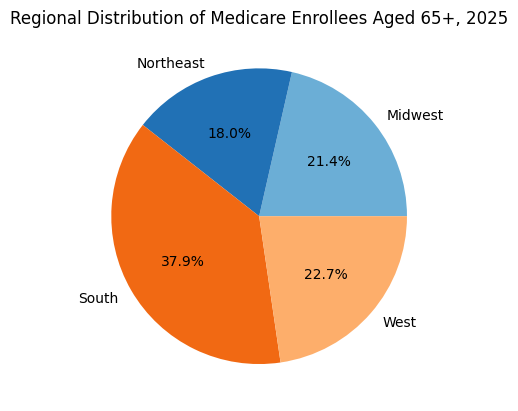

In [695]:
enrollment_2025["region"] = (
    enrollment_2025["state"].map(state_to_region)
)

region_proportion = (
    enrollment_2025.groupby("region")["enrollment_65_plus"]
    .sum()
)

region_colors = {
    "Northeast": "#2171B5",
    "Midwest": "#6BAED6",
    "South": "#F16913",
    "West": "#FDAE6B"
}

region_proportion.plot(
    kind="pie",
    autopct="%1.1f%%",
    colors=[region_colors[r] for r in region_proportion.index]
)

plt.ylabel("")
plt.title("Regional Distribution of Medicare Enrollees Aged 65+, 2025")
plt.show()


The pie chart shows the regional distribution of Medicare enrollees aged 65+. The South had the largest share, followed by the West, Midwest, and Northeast. In terms of the percentage of people aged 65+ enrolled in Medicare, the Midwest had the highest rate (96.23%), followed by the West (95.28%), Northeast (94.27%), and South (93.99%). Thus, although the South accounted for the largest share of Medicare enrollees aged 65+, it had the lowest enrollment rate among its 65+ population. The Midwest had the highest enrollment rate

**Question#2: How does regional hospital availability compare across different region population?**

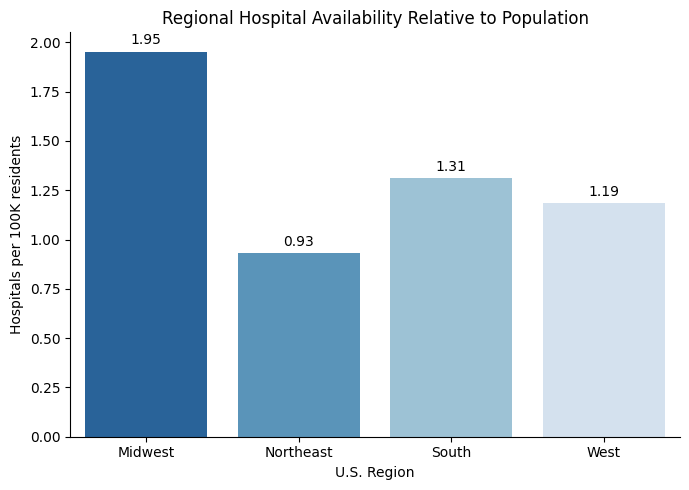

In [696]:
plt.figure(figsize=(7, 5))
ax = sns.barplot(
    data=region_summary,
    x='region',
    y='hospitals_per_100k',
    hue='region',
    palette='Blues_r',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

ax.set_title('Regional Hospital Availability Relative to Population')
ax.set_xlabel('U.S. Region')
ax.set_ylabel('Hospitals per 100K residents')
sns.despine()
plt.tight_layout()

The Midwest has the most hospitals per capita (1.95 per 100K residents), roughly double the Northeast (0.93). The South (1.31) and West (1.19) fall in between and are close to each other. Hospital availability does not appear to track regional population size: the Midwest, the second-smallest region by population, ranks first, while the South, the largest, ranks only second. Because this measure counts hospitals rather than beds, the Midwest's lead does not necessarily mean greater capacity.

**Question#3: Do states with older populations have longer emergency department total visit time?**


In [697]:
# Select 2025 enrollment data
medicare_2025 = year.loc[
    year["year"] == 2025,
    ["state", "enrollment_65_plus", "total_enrollment"]
].copy()
# Calculate the percentage of Medicare enrollees aged 65+
medicare_2025["medicare_pct_65_plus"] = (
    medicare_2025["enrollment_65_plus"]
    / medicare_2025["total_enrollment"]
    * 100
)

# Create a separate table for this analysis
medicare_ed = state_22_18[
    ["state", "ED_18", "ED_22"]
].merge(
    medicare_2025,
    on="state",
    how="left",
    validate="one_to_one"
)

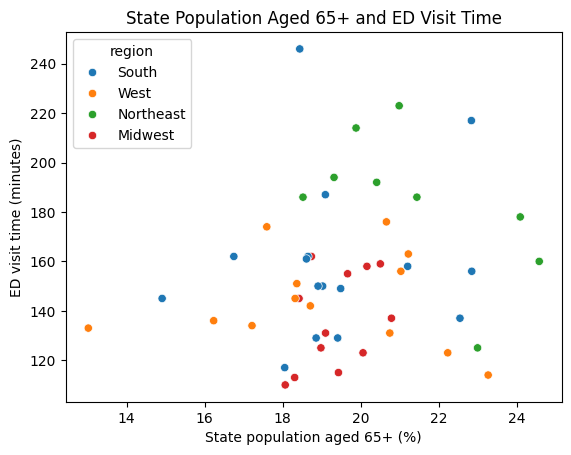

In [698]:
state_22_18["region"] = state_22_18["state"].map(state_to_region)
sns.scatterplot(data=state_22_18, x="pct_65_plus", y="ED_18", hue = 'region')
plt.xlabel("State population aged 65+ (%)")
plt.ylabel("ED visit time (minutes)")
plt.title("State Population Aged 65+ and ED Visit Time")
plt.show()

Based on the our data, there is no clear relationship between the population that is aged 65+ and OP_18b (total ED visit time). The differences appear to be driven more by region: Northeast states generally have longer ED times, while most Midwest and West states cluster lower. The South is widely spread, with several of the highest values.

**Question #4: What is the hospital bed counts per capita across the region?**

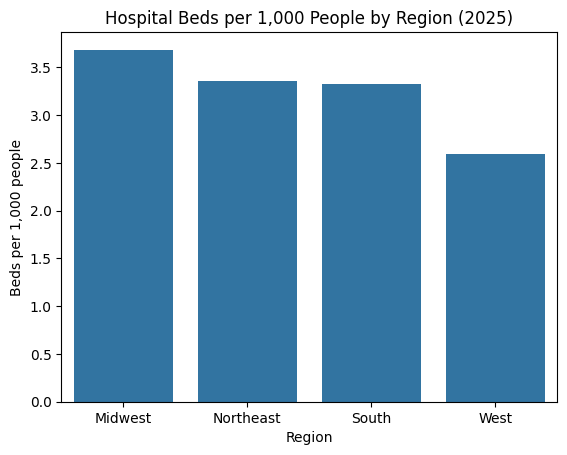

In [699]:
bed_counts_population_copy = bed_counts_population.groupby("region", as_index=False)[["Bed_Count_Total", "2025 total"]].sum()
bed_counts_population_copy["bed_count_per_region"] = (bed_counts_population_copy["Bed_Count_Total"] / bed_counts_population_copy["2025 total"]) * 1000

sns.barplot(data=bed_counts_population_copy, x="region", y="bed_count_per_region")
plt.title("Hospital Beds per 1,000 People by Region (2025)")
plt.ylabel("Beds per 1,000 people")
plt.xlabel("Region");

Hospital bed capacity per capita is fairly consistent across the Midwest, Northeast, and South (about 3.3 to 3.7 per 1,000), but the West lags at about 2.6, suggesting potential capacity gaps worth examining at the state level.

**Question #5: What is the average number of beds per hospital in each U.S. region?**

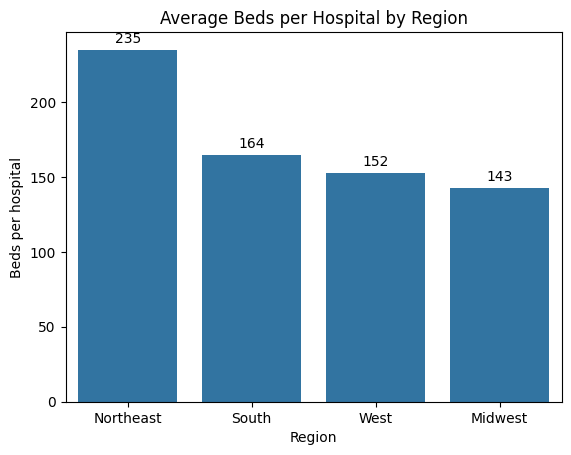

In [700]:
hosp = provider_active.loc[~provider_active["State_Abbreviation"].isin(territories_drop)].copy()

state_beds_hosp = (
    hosp.groupby("State_Abbreviation")
        .agg(total_beds=("Bed_Count_Total", "sum"),
             n_hospitals=("Bed_Count_Total", "size"))
        .reset_index()
)
state_beds_hosp["region"] = state_beds_hosp["State_Abbreviation"].map(state_to_region)

region_bph = (
    state_beds_hosp.groupby("region", as_index=False)[["total_beds", "n_hospitals"]].sum()
)
region_bph["beds_per_hospital"] = region_bph["total_beds"] / region_bph["n_hospitals"]

ax = sns.barplot(data=region_bph.sort_values("beds_per_hospital", ascending=False),
                 x="region", y="beds_per_hospital")
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
plt.title("Average Beds per Hospital by Region")
plt.xlabel("Region")
plt.ylabel("Beds per hospital");

This chart shows that the Northeast has the highest average number of beds per hospital. This connects back to our earlier analysis: the Northeast has the fewest hospitals per 100K residents (0.93, from the regional hospital availability chart) but a mid-range number of beds per 1,000 people. Together, these suggest that the Northeast has fewer but larger facilities. The hospital size vs. ED visit time scatter plot shows that larger hospitals tend to have longer ED times, so this structure may contribute to the Northeast's slower ED performance.

**Question #6: Do the 5 quality measures (OP_18a, OP_18b, OP_18c, OP_22, OP_23) for the Emergency Department perform differently across regions in 2025?**

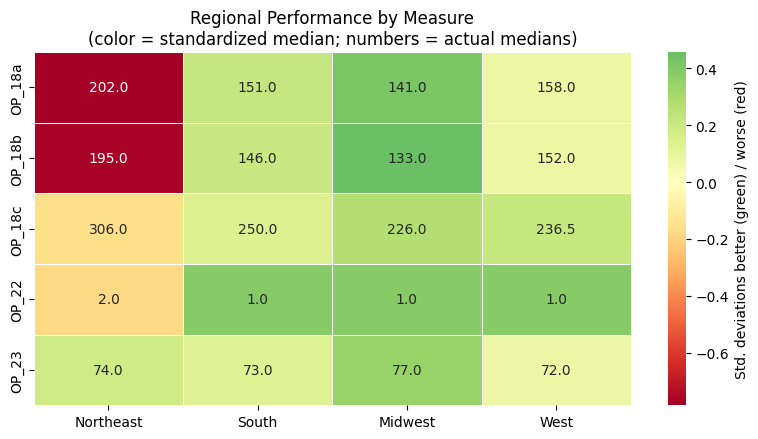

In [701]:
#2025 data are taken from 2026 datasets
region_order = ['Northeast', 'South', 'Midwest', 'West']
measures = ['OP_18a', 'OP_18b', 'OP_18c', 'OP_22', 'OP_23']
lower_is_better = ['OP_18a', 'OP_18b', 'OP_18c', 'OP_22']

#Prepare data: US states only, with Region
full_ed_hospital_data26_copy = full_ed_hospital_data26.copy()
full_ed_hospital_data26_copy['region'] = full_ed_hospital_data26_copy['state'].map(state_to_region)

full_ed_hospital_data26_copy = full_ed_hospital_data26_copy[full_ed_hospital_data26_copy['measure_id'].isin(measures)].copy()

# standardlize using Z-score: each hospital's score within its own measure, assisted by terrierGPT for the Z-score formula (Sophia)
grp = full_ed_hospital_data26_copy.groupby('measure_id')['score']
full_ed_hospital_data26_copy['Z'] = (full_ed_hospital_data26_copy['score'] - grp.transform('mean')) / grp.transform('std')

#flip the sign where lower is better, so positive (green) = better everywhere
full_ed_hospital_data26_copy.loc[full_ed_hospital_data26_copy['measure_id'].isin(lower_is_better), 'Z'] *= -1

# Median z-score and median actual score per measure and region
# Assisted by AI (Sophia) to write a function that constructs a 2D pivot table of regional medians and reindexes rows/columns to enforce consistent measure and geographic ordering
def median_table(col):
    return (full_ed_hospital_data26_copy.pivot_table(index='measure_id', columns='region', values=col, aggfunc='median')
              .reindex(index=measures, columns=region_order))

z_heat, medians = median_table('Z'), median_table('score')

# Heatmap
plt.figure(figsize=(8, 4.5))
sns.heatmap(z_heat, annot=medians, fmt='.1f', cmap='RdYlGn', center=0,
            linewidths=0.5, cbar_kws={'label': 'Std. deviations better (green) / worse (red)'})
plt.title('Regional Performance by Measure\n(color = standardized median; numbers = actual medians)')
plt.xlabel('')
plt.ylabel('')
plt.tight_layout()

The ED measure heatmap shows that the Midwest performs best overall. The Midwest has the lowest median times on OP-18a, OP-18b, and OP-18c, and ties with the South and West on OP-22. At the same time, patients in the Northeast performs worst on OP-18a, OP-18b, OP-18c, and OP-22, meaning that its median ED visit lasts longer (overall, for discharged patients, and for psychiatric patients) and a higher share of patients leave without being seen. While there's not a big difference in OP_23 (how quickly stroke patients get imaging read). However, this comparison does not yet account for hospital size. Busier emergency departments naturally have longer waits, so the Northeast's results could simply reflect larger, busier hospitals. To find out, we need to further compare hospitals of similar size.

**Question#7: How has ED visit time(OP-18b) changed across regions over time?**

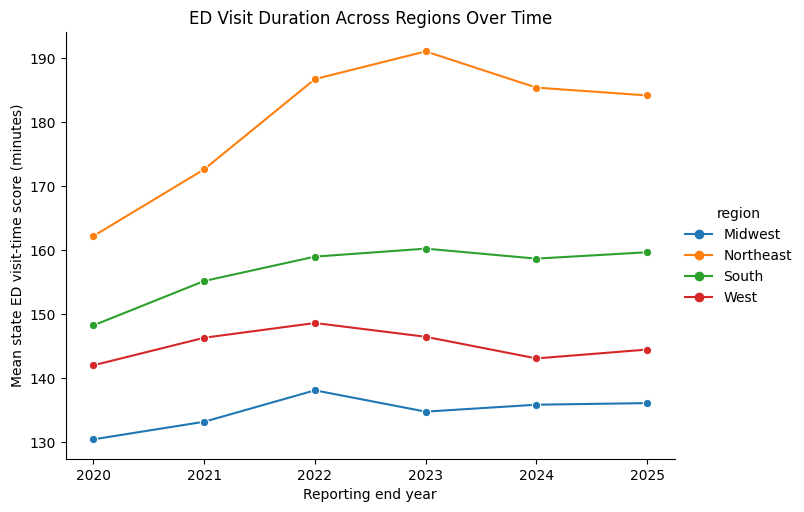

In [702]:
state_to_region = {
    state: region
    for region, states in regions.items()
    for state in states
}
ed_state = op18_state_data_years.copy()
ed_state["region"] = ed_state["state"].map(state_to_region)
ed_state["score"] = pd.to_numeric(ed_state["score"])

# Calculate the average state score within each region and year
regional_year = (
    ed_state.groupby(["region", "year"], as_index=False)
    .agg(mean_score=("score", "mean"))
)

sns.relplot(
    data=regional_year,
    x="year",
    y="mean_score",
    hue="region",
    kind="line",
    marker="o",
    height=5,
    aspect=1.4
)

plt.xlabel("Reporting end year")
plt.ylabel("Mean state ED visit-time score (minutes)")
plt.title("ED Visit Duration Across Regions Over Time")
plt.show()

Over the available timeframe, the Midwest has the best performance on average time discharged patients spend in the ED from arrival to departure (OP_18b), followed by the West, South, and Northeast. This ranking holds in every year, but the Northeast has pulled further away from the others: its average rose from about 162 minutes in 2020 to a peak of about 191 in 2023, before easing slightly. We also see an upward trend in ED times since 2020 and a steady decline since around 2023. Suggesting that ED times increased after covid and the healthcare systems have not fully recovered since then.

**Question #8: Do rural and urban hospitals differ in emergency department efficiency (is there a systematic challenge) across the certain period? Testing it by using measurement OP-18b, OP-22.**

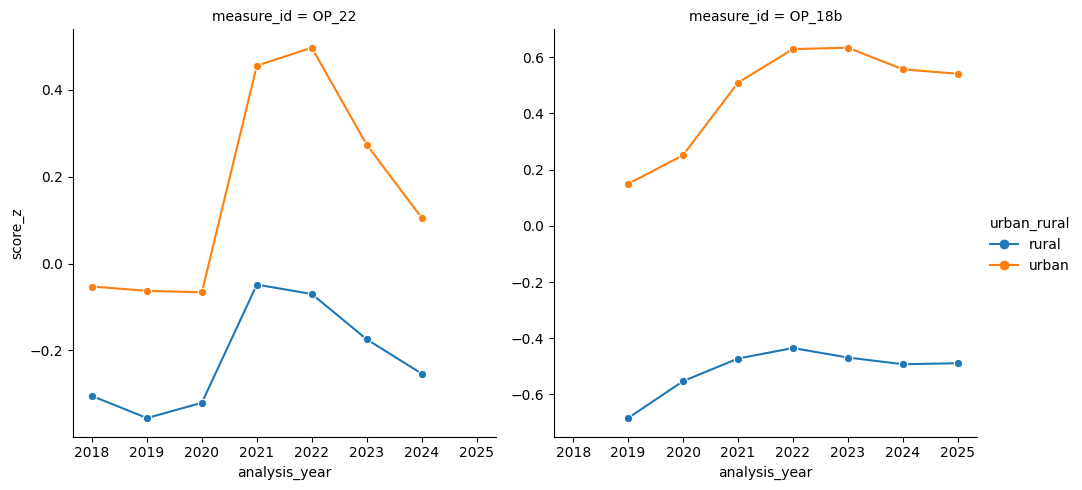

In [703]:
#keep the year from the end_date
hospital_with_ruca['analysis_year'] = hospital_with_ruca['end_date'].dt.year
#create a dataset that only include the target measure_id
study_data = hospital_with_ruca[hospital_with_ruca['measure_id'].isin(['OP_18b', 'OP_22'])].copy()

summary = (study_data.groupby(['analysis_year', 'measure_id', 'urban_rural'],dropna=False)['score'].agg(['count', 'mean', 'median']).reset_index())

#handle OP-18b and OP-22 seperately- groupby
#standardize score within each measure across the study period
study_data['score_z'] = study_data.groupby('measure_id')['score'].transform(lambda s: (s - s.mean()) / s.std())

# Average standardized score by year, measure, and rural/urban status; AI clue (Sophia): average hospital z-scores to show the group-level yearly trends
annual_z = (study_data.groupby(['analysis_year', 'measure_id', 'urban_rural'],as_index=False)['score_z'].mean())

# Plot each measure in its own panel
sns.relplot(data=annual_z,
    x='analysis_year',
    y='score_z',
    hue='urban_rural',
    col='measure_id',
    kind='line',
    marker='o',
    facet_kws={'sharey': False}); # AI suggestion (Sophia): use the same y-axis scale in both panels to make standardized scores easier to compare.

OP-18b (median time to discharge) and OP-22 (percentage of patients who left without being seen) are both lower-is-better measures. In every year, urban EDs had higher standardized scores than rural EDs, suggesting more operational strain in urban settings. Differences in patient volume, case mix, and staffing may contribute to this gap, but this analysis cannot confirm that. Scores for both groups also rose around 2021 to 2022, overlapping with the COVID-19 pandemic. This may reflect pandemic-related ED strain, though again the analysis cannot directly show that the pandemic caused the pattern.

**Question #9: Which five states have the highest total emergency department wait times?**

In [704]:
op18_state_data_2025=op18_state_data_years[op18_state_data_years['year']==2025].copy()
op18_state_data_2025.sort_values(by='score', ascending=False).head()

,state,condition,measure_id,measure_name,score,footnote,year
288,DC,Emergency Department,OP_18b,Average (median) time patients spent in the em...,303.0,NaN,2025
302,MD,Emergency Department,OP_18b,Average (median) time patients spent in the em...,246.0,NaN,2025
323,RI,Emergency Department,OP_18b,Average (median) time patients spent in the em...,223.0,NaN,2025
289,DE,Emergency Department,OP_18b,Average (median) time patients spent in the em...,217.0,NaN,2025
301,MA,Emergency Department,OP_18b,Average (median) time patients spent in the em...,214.0,NaN,2025


**Question #10: Which Northeast state has the longest ED time, and does its elderly enrollment explain it?**

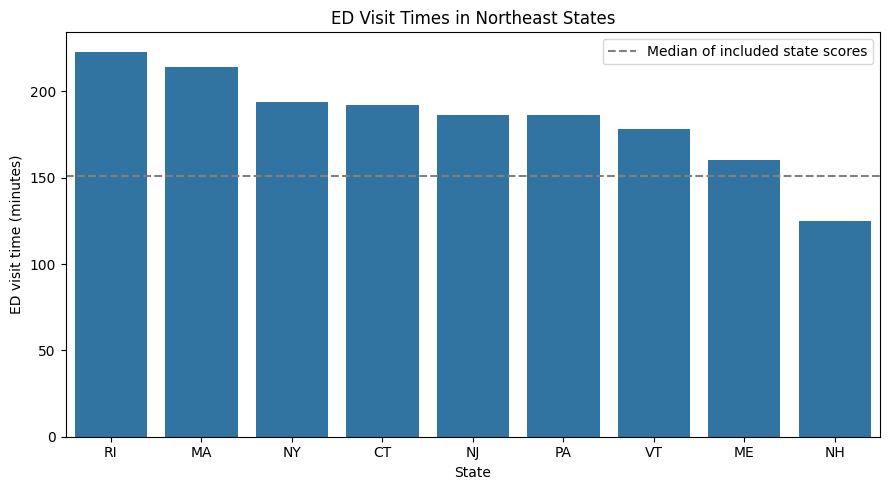

In [705]:
northeast_performance = state_22_18.loc[
    state_22_18["region"] == "Northeast",
    ["state", "ED_18"]
]

order = northeast_performance.sort_values(
    "ED_18", ascending=False
)["state"]

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=northeast_performance,
    x="state",
    y="ED_18",
    order=order,
    ax=ax
)

ax.axhline(
    state_22_18["ED_18"].median(),
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label="Median of included state scores"
)

ax.set_title("ED Visit Times in Northeast States")
ax.set_xlabel("State")
ax.set_ylabel("ED visit time (minutes)")
ax.legend()

plt.tight_layout()
plt.show()

As from our above analysis, the Northeast experienced long total wait times in the ED. Hence, we dive deeper into which states have the longest total wait times. It shows that Rhode Island and Massachusetts have the longest ED times in the region, followed by New York and Connecticut. New Hampshire is the only Northeast state below the national median. These differences are not explained by the size of the elderly Medicare population: Rhode Island has one of the smallest 65+ enrollments yet the longest wait, while New York and Pennsylvania, with the largest enrollments, sit mid-pack. This suggests the delays are driven by factors other than elderly demand, such as ED crowding, hospital operations, or staffing.

**Question #11: Which five states have the most total hospital beds per 1,000 residents in 2025?**

In [706]:
bed_counts_population['Per_1000'] = (bed_counts_population['Bed_Count_Total']/bed_counts_population['2025 total'])*1000
per_1000_state = bed_counts_population.pivot_table(
    values="Per_1000",
    index="State_Abbreviation",
)
top5 = per_1000_state.sort_values("Per_1000", ascending=False).head(5)
top5

,Per_1000
State_Abbreviation,
MS,5.401326
WV,4.963278
KS,4.791116
AR,4.778324
LA,4.729863


Mississippi has the highest reported bed supply at 5.40 beds per 1,000 residents, followed by West Virginia at 4.96.

**Question #12: What is the average state-level number of hospital beds per 1,000 residents in each region?**

In [707]:
beds_per_1000 = bed_counts_population.pivot_table(
    values="Per_1000",
    index="region",
    aggfunc="mean"
)
beds_per_1000

,Per_1000
region,
Midwest,3.808736
Northeast,3.223356
South,3.707682
West,2.740940


The Midwest has the highest average state bed rate at 3.81 beds per 1,000 residents, followed by the South at 3.71. The Northeast averages 3.22, while the West has the lowest rate at 2.74.

**Question #13: Is hospital size, measured by total beds, associated with ED visit time (OP_18b) among matched hospitals?**

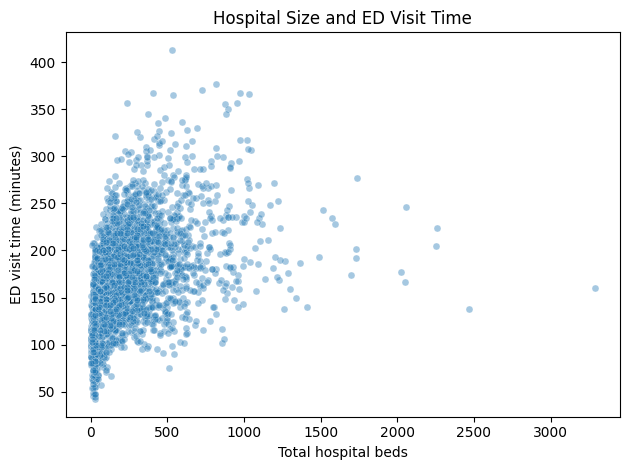

In [708]:
ed_beds = hospital_all.loc[(hospital_all["measure_id"] == "OP_18b") & (hospital_all["provider_match"] == "both")].copy()
sns.scatterplot(data=ed_beds, x="Bed_Count_Total", y="score", alpha=0.4, s=25)

plt.xlabel("Total hospital beds")
plt.ylabel("ED visit time (minutes)")
plt.title("Hospital Size and ED Visit Time")
plt.tight_layout()
plt.show()

This scatterplot shows no strong, clear relationship between total hospital beds and ED visit time. Most hospitals have fewer than 500 beds, and their reported ED visit times vary, with many between roughly 100 and 250 minutes. Some hospitals with larger bed counts also have longer visit times, but there are some exceptions and substantial variation across hospitals of similar size.

**Question #14: How does median ED visit time vary by hospital size category across regions, and how many hospitals are in each region–size group?**

In [709]:
ed_beds["region"] = ed_beds["state"].map(state_to_region)
ed_beds["size"] = pd.cut(ed_beds["Bed_Count_Total"], bins=[0, 100, 300, float("inf")],
    labels=["Under 100 beds", "100–299 beds", "300+ beds"], right=False)

In [710]:
region_size_summary = (ed_beds.groupby(["region", "size"], observed=True).agg(median_ed_minutes=("score", "median"),hospitals=("facility_id", "nunique")).reset_index())
region_size_summary

,region,size,median_ed_minutes,hospitals
0,Midwest,Under 100 beds,117.0,775
1,Midwest,100–299 beds,169.0,262
2,Midwest,300+ beds,189.0,215
3,Northeast,Under 100 beds,140.0,124
4,Northeast,100–299 beds,197.0,192
5,Northeast,300+ beds,219.0,172
6,South,Under 100 beds,120.0,696
7,South,100–299 beds,162.0,469
8,South,300+ beds,184.0,365
9,West,Under 100 beds,125.0,385


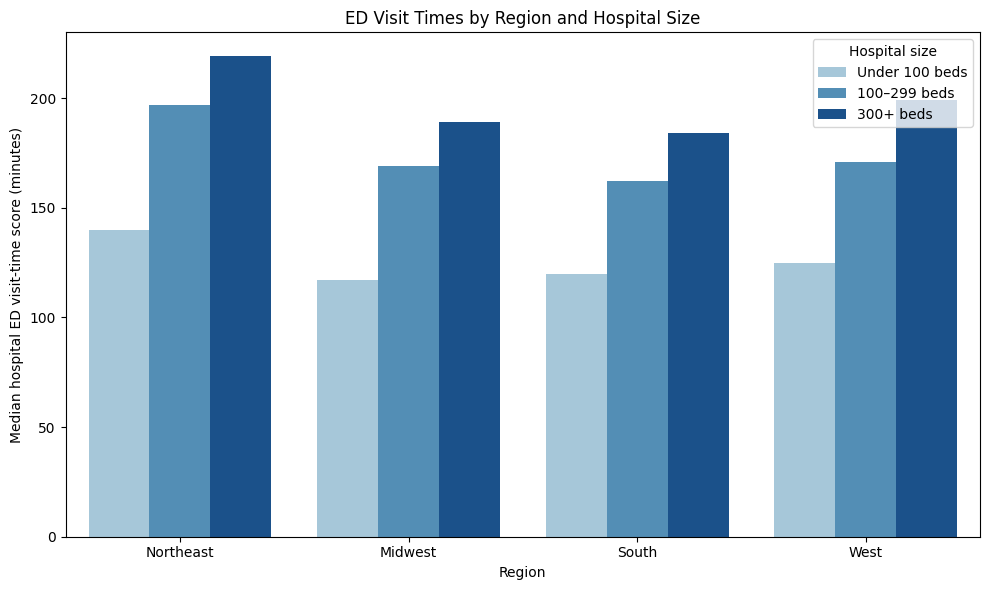

In [711]:
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=region_size_summary, x="region", y="median_ed_minutes",
    hue="size", order=["Northeast", "Midwest", "South", "West"],
    hue_order=["Under 100 beds", "100–299 beds", "300+ beds"],
    errorbar=None, palette={"Under 100 beds": "#9ECAE1", "100–299 beds": "#4292C6", "300+ beds": "#08519C"}
)

plt.xlabel("Region")
plt.ylabel("Median hospital ED visit-time score (minutes)")
plt.title("ED Visit Times by Region and Hospital Size")
plt.legend(title="Hospital size")
plt.tight_layout()
plt.show()

Across all regions, larger hospitals have higher ED visit times: hospitals with 300+ beds have the highest, and those with under 100 beds have the lowest. In general, the Northeast has the highest median in each size category. This suggests an association between hospital size and longer ED visits, but does not establish causation.

**Question #15: How does hospital-bed availability per 1,000 residents vary across U.S. states?**

In [712]:
beds_by_state = (
    provider_active
    .groupby("State_Abbreviation")["Bed_Count_Total"]
    .sum(min_count=1)
    .reset_index()
    .rename(columns={
        "State_Abbreviation": "state",
        "Bed_Count_Total": "total_beds"
    })
)

In [713]:
state_capacity = population[
    ["state", "2025 elder", "2025 total"]
].merge(
    beds_by_state,
    on="state",
    how="left",
    validate="one_to_one"
)
state_capacity["pct_65_plus"] = (
    state_capacity["2025 elder"]
    / state_capacity["2025 total"]
    * 100
)
state_capacity["beds_per_1000"] = (
    state_capacity["total_beds"]
    / state_capacity["2025 total"]
    * 1000
)

In [714]:
fig_beds = px.choropleth(
    state_capacity,
    locations="state",
    locationmode="USA-states",
    color="beds_per_1000",
    scope="usa",
    color_continuous_scale="Blues",
    labels={"beds_per_1000": "Beds per 1,000 residents"},
    title="Hospital Beds per 1,000 Residents",
    hover_data={"beds_per_1000": ":.2f"}
)

fig_beds.show()

The map suggests hospital-bed availability varies by state, with several Midwest and Southern states showing higher beds per 1,000 residents than many lighter-shaded states.

**Question #16: How is the spread of population that is aged 65+ looks like across U.S. states?**

In [715]:
fig_population = px.choropleth(
    state_capacity,
    locations="state",
    locationmode="USA-states",
    color="pct_65_plus",
    scope="usa",
    color_continuous_scale="Oranges",
    labels={"pct_65_plus": "Population aged 65+ (%)"},
    title="State Population Aged 65+ (%) — 2025",
    hover_data={"pct_65_plus": ":.1f"}
)
fig_population.show()

The shows the residents aged 65+ varies across states, appearing highest in parts of the Northeast and lower in some western and southern states. Maine appears among the highest, while Utah appears among the lowest. This map shows the percentage of each state’s population aged 65+, not the total number of older residents—so a state with a high percentage may still have fewer older people overall than a more populous state.

**Question #17: How did the number of Medicare enrollees aged 65+ compare with the total population aged 65+ across U.S. regions from 2020 to 2025?**

In [716]:
region_order = ["Northeast", "Midwest", "South", "West"]
colors = ["#4C78A8", "#F2A541", "#59A14F", "#B279A2"]
years_to_plot = list(range(2020, 2026))
population_long = population.melt(
    id_vars="state",
    value_vars=[f"{y} elder" for y in years_to_plot],
    var_name="year",
    value_name="population_65_plus"
)

population_long["year"] = (
    population_long["year"].str[:4].astype(int)
)

population_long["region"] = (
    population_long["state"].map(state_to_region)
)

population_long = population_long.loc[
    population_long["region"].notna()
    & ~population_long["state"].isin(["PR", "VI", "GU", "AS", "MP"])
].copy()

comparison = population_long.merge(
    year[["state", "year", "enrollment_65_plus"]],
    on=["state", "year"],
    how="left",
    validate="one_to_one"
)
if comparison[["population_65_plus", "enrollment_65_plus"]].isna().any().any():
    raise ValueError(
        "Some state-year counts are missing. Check comparison before plotting."
    )
regional_counts = (
    comparison.groupby(["year", "region"])[
        ["enrollment_65_plus", "population_65_plus"]
    ]
    .sum(min_count=1)
    .reset_index()
)
medicare_bars = (
    regional_counts.pivot(
        index="year",
        columns="region",
        values="enrollment_65_plus"
    )
    .reindex(index=years_to_plot, columns=region_order)
    / 1_000_000
)

population_bars = (
    regional_counts.pivot(
        index="year",
        columns="region",
        values="population_65_plus"
    )
    .reindex(index=years_to_plot, columns=region_order)
    / 1_000_000
)

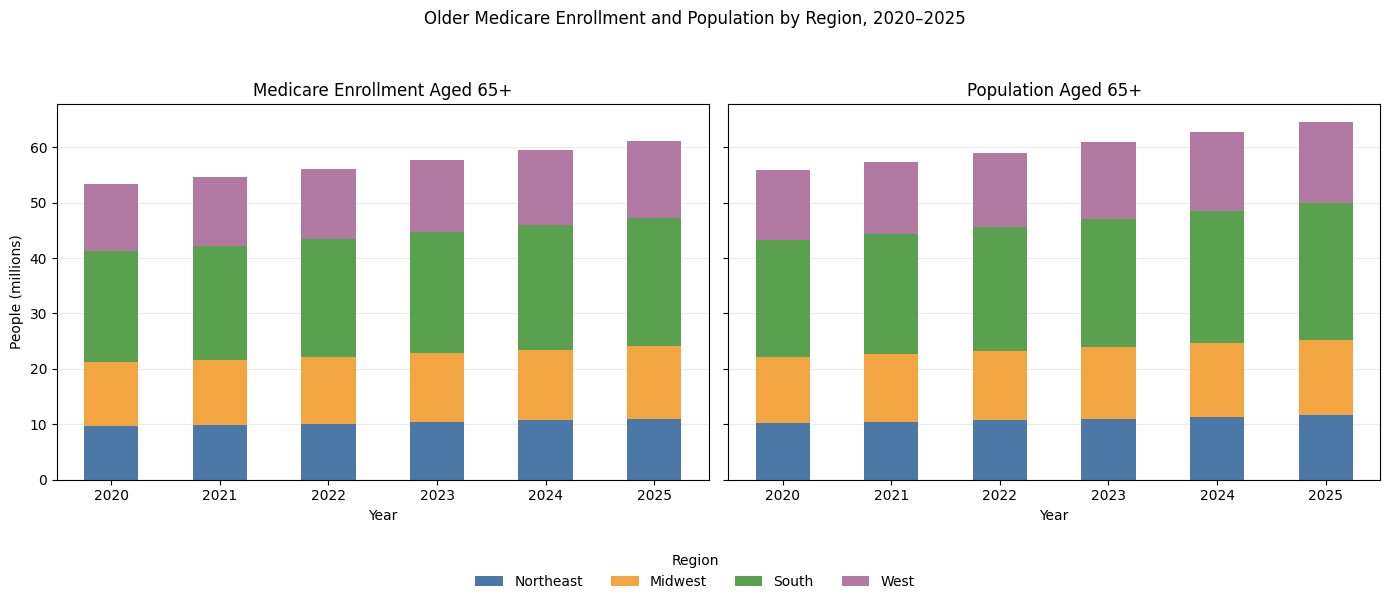

In [717]:
fig, (ax1, ax2) = plt.subplots(1, 2,figsize=(14, 6),sharey=True)

medicare_bars.plot(
    kind="bar",
    stacked=True,
    color=colors, ax=ax1, legend=False, rot=0)

population_bars.plot(
    kind="bar",
    stacked=True,
    color=colors,
    ax=ax2,
    legend=False,
    rot=0
)

ax1.set_title("Medicare Enrollment Aged 65+")
ax2.set_title("Population Aged 65+")

ax1.set_ylabel("People (millions)")

for ax in (ax1, ax2):
    ax.set_xlabel("Year")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)

handles, labels = ax1.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    title="Region",
    loc="lower center",
    ncol=4,
    frameon=False
)

fig.suptitle("Older Medicare Enrollment and Population by Region, 2020–2025")
plt.tight_layout(rect=[0, 0.10, 1, 0.94])
plt.show()

From 2020 to 2025, both the number of Medicare enrollees aged 65+ and the total population aged 65+ increased in all regions. The South contributed the largest counts in both charts, while the Northeast contributed the smallest.

**Question #18: How do hospital count, median ED visit time, and median size differ by ownership type?**

In [718]:
ownership_summary = (
    ed_beds.groupby("Ownership_Type", dropna=False)
    .agg(
        hospitals=("facility_id", "nunique"),
        median_ed_minutes=("score", "median"),
        median_beds=("Bed_Count_Total", "median")
    )
    .sort_values("hospitals", ascending=False)
)

display(ownership_summary.round(1))

,hospitals,median_ed_minutes,median_beds
Ownership_Type,,,
Private nonprofit,2016,159.0,126.0
Private for-profit,590,140.0,143.5
Hospital district / authority,467,127.0,31.0
Local,334,127.0,25.0
Other,294,152.0,112.5
Church,245,159.0,197.0
State,47,179.0,420.0
Physician ownership,33,140.0,43.0
Unknown / missing,23,139.0,342.0


Private nonprofit hospitals are the most in the US, with 2,016 hospitals and a median ED visit-time score of 159 minutes. State-owned hospitals have the highest median score at 179 minutes.

**Question #19: How does the typical hospital size, measured by median total beds, vary by ownership type?**

In [719]:
beds_by_ownership = (
    provider_active.groupby("Ownership_Type")["Bed_Count_Total"]
    .median()
    .sort_values(ascending=False)
)

beds_by_ownership

,Bed_Count_Total
Ownership_Type,
State,175.0
Church,170.0
Private nonprofit,107.5
Other,106.0
Private for-profit,68.0
Unknown / missing,60.0
Federal,45.0
Hospital district / authority,26.0
Local,25.0


State-owned and church-owned hospitals have the largest median bed counts at 175 and 170, respectively. Physician-owned hospitals have the smallest median at 24.5 beds.

**Question #20: How are hospitals with the five most common ownership types distributed across U.S. regions?**

In [720]:
ownership_region = provider_active.copy()

ownership_region["region"] = (
    ownership_region["State_Abbreviation"].map(state_to_region)
)
ownership_region = ownership_region.loc[
    ownership_region["region"].notna()& ~ownership_region["State_Abbreviation"].isin(["PR", "VI", "GU", "AS", "MP"])].copy()
top_5 = (
    ownership_region.groupby("Ownership_Type")["CCN"]
    .nunique()
    .nlargest(5)
    .index
)
ownership_pivot = (
    ownership_region.loc[
        ownership_region["Ownership_Type"].isin(top_5)
    ]
    .pivot_table(
        index="Ownership_Type",
        columns="region",
        values="CCN",
        aggfunc="nunique",
        fill_value=0
    )
    .reindex(
        index=top_5,
        columns=["Northeast", "Midwest", "South", "West"],
        fill_value=0
    )
)

ownership_pivot["Total"] = ownership_pivot.sum(axis=1)
ownership_pivot.loc["Total"] = ownership_pivot.sum(axis=0)

ownership_pivot

region,Northeast,Midwest,South,West,Total
Ownership_Type,,,,,
Private nonprofit,452,781,775,426,2434
Private for-profit,124,256,911,313,1604
Unknown / missing,104,156,275,194,729
Hospital district / authority,3,77,286,149,515
Local,16,204,117,53,390
Total,699,1474,2364,1135,5672


Private nonprofit hospitals are the largest recorded ownership category overall, with 2,437 facilities. Private for-profit hospitals lead in the South, with 916 facilities.

**Question #21: How do hospital-bed availability and the share of residents aged 65+ compare across U.S. regions?**

In [721]:
regional_source = state_capacity.copy()
regional_source["region"] = (regional_source["state"].map(state_to_region))
regional_capacity = (regional_source.groupby("region")[["total_beds", "2025 elder", "2025 total"]].sum(min_count=1).reset_index())
regional_capacity["beds_per_1000"] = (regional_capacity["total_beds"]/ regional_capacity["2025 total"]* 1000)
regional_capacity["pct_65_plus"] = (regional_capacity["2025 elder"]/ regional_capacity["2025 total"]* 100)
region_map = regional_source[["state", "region"]].merge(regional_capacity,on="region", how="left",validate="many_to_one")

regional_capacity.round(2)

,region,total_beds,2025 elder,2025 total,beds_per_1000,pct_65_plus
0,Midwest,256732.0,13626957,69675813,3.68,19.56
1,Northeast,194689.0,11662579,57998188,3.36,20.11
2,South,441279.0,24669307,132540071,3.33,18.61
3,West,206721.0,14563822,79812472,2.59,18.25


The Northeast has the highest older population share at 20.11%, yet fewer beds per 1,000 residents than the Midwest: 3.36 versus 3.68. The West has the lowest bed supply at 2.59 per 1,000 residents.

#**Conclusion**
****

We compared emergency department (ED) performance across regions and between rural and urban hospitals, and we also looked at how the older population fits into the picture. Here are the four main points from our analysis.

<br>1. Emergency department (ED) visits time are longest in the Northeast.

The typical ED visit in the Northeast lasts about 195 minutes (over 3 hours) from arrival to departure for discharged patients, compared with about 133 minutes in the Midwest, the fastest region. Hospital size, bed supply and the size of the older population do not explain the gap. On average, Northeast hospitals are the largest, with about 235 beds each, yet the region still had the longest visits among small, medium and large hospitals alike. We recommend that Northeast hospitals and state health departments investigate likely causes, such as staffing, how many patients arrive, and how long admitted patients wait in the ED for a hospital bed. To do this, each hospital would need data on staffing levels, patient volume and admitted-patient waiting times for the same reporting periods. Our data shows where delays are longest but not why, so these causes are possibilities, not findings.


<br>2. Urban hospitals have slower ED visits time, so they are a good place to focus efforts to improve ED flow.

Our analysis shows that urban hospitals had longer ED visits than rural hospitals in every year we examined, and the gap in visit length has not narrowed over time. This is what we would expect, since urban hospitals tend to be larger and larger hospitals tend to have longer visits, but it matters because the gap persists. We recommend that hospital quality teams, especially in urban areas, regularly track visit length and the share of patients who leave without being seen. As a next step, they should add patient volume and patient characteristics to the analysis, and use matching reporting periods, so urban and rural hospitals can be compared fairly. A further step would be to identify which urban hospitals perform well and learn from their practices.

<br>3. Hospital capacity looks different depending on how you measure it.

The Northeast has the fewest hospitals per 100,000 residents (0.93, versus 1.95 in the Midwest), but its hospitals are the largest, so its number of beds per 1,000 people (about 3.4) is similar to the South and Midwest (3.3 to 3.7). The West has the fewest beds per 1,000 people (about 2.6), and all Western states except Wyoming fall below the national level. Counting hospitals alone can therefore mislead: a region with few hospitals may still have plenty of beds. We recommend that regional planners look at the number of hospitals, beds per hospital and beds per person together, and give extra attention to the West. As a next step, they should collect data on staffed beds, occupancy and current bed availability before recommending capacity changes. Our hospital counts and bed totals came from different hospital lists, and reported beds are not the same as staffed ED capacity, so these figures are indicators, not exact measures.

<br>4. The Midwest is the region that performed the best in the overall performance efficiency measures.

Midwest has an average best score in performance measure within the Emergency Department compared to the other regions. It also has the highest hospital per capita at 1.95 hospitals per 100,000 residents and the highest bed count. When compared to the elderly population in the Midwest region, it does not have the largest number of elderly population. This could indicate that they have a handful of resources and the elderly population is not saturated compared to the amount of hospitals and beds they have.

#**Challenges**
****

<br>1. Our data does not measure the target group (elderly 65+) directly.

Our problem statement focuses on patients aged 65 and older, but the public ED measures we used cover patients of all ages and are not broken out by age. The only age-specific information came from population and Medicare datasets, so we used each state’s older-population share and Medicare enrollment, and both are imperfect. We can show how regions compare overall and whether a larger older population lines up with longer ED visits (in our scatterplots, it did not show a clear pattern), but we cannot show how older patients themselves experience the ED.


<br>2. Our data measures only some aspects of hospital efficiency.

Our data covers the availability of hospitals that include the number of hospitals, bed count, ED visit time and the share of patients who leave without being seen. However, in reality, there are many ways we could measure hospital efficiency. This may include staffing levels, the hospital’s internal system, hospital speciality services etc. Therefore, the conclusion in efficiency we concluded dictates from only a few factors rather than all aspects.

<br>3. Some of our datasets reported different years.

There are several datasets that contain measurements in different years. For instance, OP18b measurement includes data from the year 2020-2025, meanwhile OP22 measurement includes data from year 2019-2024. This gap and difference in year could limit the analysis and make it more difficult to compare across them year by year.

<br>4. Missing and unreported values.

 In the “Timely and Effective Care by Hospital” and “Timely and Effective Care by State” datasets, some scores were missing. These gaps are unlikely to be random. They usually come with a footnote explaining why, such as a small patient sample or a short reporting period, which means the hospitals without scores may differ systematically from those with scores. Because the values exist but are not available to us, we could not compare the two groups. We kept the missing-score rows and their footnotes in the cleaned dataset but left them out of the score calculations. We did not impute values, since a guessed score would hide the reason the data was suppressed. As a result, our findings on total ED visit time and patients who leave without being seen reflect only hospitals and states with reported scores, not real changes in performance.

#**References**
****
*   Centers for Medicare & Medicaid Services. “Hospital Downloadable Database Data Dictionary.” July 2026. https://data.cms.gov/provider-data/sites/default/files/data_dictionaries/hospital/HOSPITAL_Data_Dictionary.pdf.

*   Centers for Medicare & Medicaid Services. “Medicare Monthly Enrollment.” Accessed October 18, 2026. https://data.cms.gov/summary-statistics-on-beneficiary-enrollment/medicare-and-medicaid-reports/medicare-monthly-enrollment/data.

*   Centers for Medicare & Medicaid Services. “Provider of Services File — Quality Improvement and Evaluation System.” Accessed October 18, 2026. https://data.cms.gov/provider-characteristics/hospitals-and-other-facilities/provider-of-services-file-quality-improvement-and-evaluation-system.

*   National Bureau of Economic Research. “Centers for Medicare & Medicaid Services (CMS) Hospital Compare Data.” Accessed October 18, 2026. https://www.nber.org/research/data/centers-medicare-medicaid-services-cms-hospital-compare-data.

*   U.S. Census Bureau. “State Population by Characteristics: 2020–2025.” June 2026. https://www.census.gov/data/tables/time-series/demo/popest/2020s-state-detail.html.

*   U.S. Department of Agriculture, Economic Research Service. “Rural-Urban Commuting Area Codes.” Accessed October 18, 2026. https://www.ers.usda.gov/data-products/rural-urban-commuting-area-codes.

* KFF Health News. "Stranded in the ER, Seniors Await Hospital Care and Suffer Avoidable Harm." Accessed October 18, 2026. https://kffhealthnews.org/aging/emergency-room-boarding-older-adults-harm/

* Meals on Wheels America. "By the Numbers: America's Aging Population Fact Sheet."Accessed October 18, 2026. https://www.mealsonwheelsamerica.org/research/americas-aging-population-fact-sheet/

#**Gen AI Disclosure**
****

### Vicky – Generative AI Disclosure

I used ChatGPT to assist with debugging Python code, troubleshooting errors, and identifying appropriate data sources through online research. Additionally, I used ChatGPT to help finalize the overall notebook by reviewing its organization, improving consistency, and preparing the Data Dictionary to clearly document the cleaned datasets and their variables. All AI-assisted outputs were reviewed and verified before being incorporated into the final project.

### Muntira (View) Samalapa - Generative AI Disclosure
I used ProfAI and Claude to understand the concepts and syntax of graphs and data cleaning. Additionally, I used ProfAI to assist with debugging errors message to understand what parts of the code was missing or needs fix. I worked mostly on creating pie chart of medicare registered elderly and removing missing values of Medicare Monthly enrollment.

###Sophia - Generative AI Disclosure
I used ProfAI at the start of the project to learn the steps involved in data cleaning and decide which ones to include. Later, I used TerrierAI to help debug error messages and identify what I was missing. I reviewed all AI-assisted output after running the code. I also used Claude to check the grammar of the insights I had written. I worked mostly on data cleaning and graphs for the "Timely and Effective Care by Hospital" and "Timely and Effective Care by State" datasets, including parts of Data Merging 1 and 4 and all of Data Merging 2, 3 and 6.

###Ateh - Generative AI Disclosure
I Used ProfAI, Claude and ChatGPT. I used ProfAI to look up specific syntax from the course, ask about project guidelines and to find out how certain syntax works. I also used ChatGPT and Claude to look up code functions I was already familiar with aswell as specific variations of that syntax that I need and was not aware about. I also used these chatbots, to enhance graphing by asking for specific color codes to use in graph syntax.

###Lujia Shao (Lydia) - Generative AI Disclosure
I used ChatGPT to troubleshoot code errors. I also used ChatGPT to enhance the structure of the conclusion and challenges sections, such as improving organization and identifying gaps. And I also used Grammarly to improve my English grammar skills.